# AngioCAD MedicalSAM3 + mLLM — LCX 1-class smoke experiment

**목적:** 15개 혈관 구간 전체로 확장하기 전에 LCX 하나만 대상으로
`mLLM visual grounding → Medical-SAM3 box prompt`가 작동하는지 확인한다.

비교 대상:

1. Medical-SAM3 고정 text prompt: `left circumflex coronary artery main trunk`
2. mLLM이 고른 프레임과 bounding box를 사용한 Medical-SAM3 box prompt

기본 사례는 AngioCAD **환자 6 / 좌관상동맥 series 5**이다. 엑셀 정답은
mLLM 실행 후에만 비교하며 프롬프트에는 절대 넣지 않는다. 이 노트북은 연구용
smoke test이며 임상 진단용이 아니다.


In [ ]:
#@title 00. Google Drive 연결 및 한 곳에서 경로 설정

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json
import os
import random
import re
import shutil
import subprocess
import sys
import time

PROJECT_DIR = Path(
    "/content/drive/MyDrive/"
    "[MacGyver]최종프로젝트/"
    "03_data/AngioCAD"
)

# 첫 smoke case. 다른 환자로 바꿀 때는 이 두 값만 먼저 변경한다.
PATIENT_ID = 6
SERIES_ID = 5
N_MLLM_FRAMES = 3

LABELS_PATH = PROJECT_DIR / "AngioCAD_Labels.xlsx"
RAR_FIRST_PART = PROJECT_DIR / "AngioCAD_Dataset.part1.rar"
MEDSAM3_WEIGHTS_DIR = PROJECT_DIR / "external_data" / "MedicalSAM3"
OUTPUT_DIR = (
    PROJECT_DIR / "dca1_results" / "medicalsam3_mllm_lcx"
    / f"patient_{PATIENT_ID:03d}_series_{SERIES_ID}"
)

MEDSAM3_REPO_DIR = Path("/content/Medical-SAM3")
LOCAL_CASE_ROOT = Path("/content/AngioCAD_LCX_case")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MEDSAM3_WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

gpu_info = subprocess.run(
    ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
    capture_output=True,
    text=True,
)
assert gpu_info.returncode == 0, "Colab 런타임을 GPU로 설정하세요."
print("GPU:", gpu_info.stdout.strip())
print("PROJECT_DIR:", PROJECT_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)


Mounted at /content/drive
GPU: NVIDIA L4, 23034 MiB
PROJECT_DIR: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD
OUTPUT_DIR: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/dca1_results/medicalsam3_mllm_lcx/patient_006_series_5


In [ ]:
#@title 01. 공식 Medical-SAM3 clone 및 필요한 패키지 설치

MEDSAM3_REPO_URL = "https://github.com/AIM-Research-Lab/Medical-SAM3.git"

if MEDSAM3_REPO_DIR.exists():
    print("기존 Medical-SAM3 clone을 재사용합니다:", MEDSAM3_REPO_DIR)
else:
    subprocess.run(
        ["git", "clone", "--depth", "1", MEDSAM3_REPO_URL, str(MEDSAM3_REPO_DIR)],
        check=True,
    )

def pip_install(*packages):
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *packages],
        check=True,
    )

# 공식 저장소의 numpy==1.26 표기 문제를 피하기 위해 --no-deps로 설치한다.
# pip_install("numpy==1.26.4")
pip_install("--no-deps", "-e", str(MEDSAM3_REPO_DIR))
pip_install(
    "timm>=1.0.17",
    "tqdm",
    "ftfy==6.1.1",
    "regex",
    "iopath>=0.1.10",
    "typing_extensions",
    "huggingface_hub",
    "opencv-python-headless",
    "scikit-image",
    "matplotlib",
    "pandas",
    "pillow",
    "openpyxl",
    "fvcore",
    "fairscale",
    "einops",
    "torchmetrics",
    "hydra-core",
    "transformers>=4.49.0",
    "accelerate",
    "qwen-vl-utils",
    "bitsandbytes",
)

commit_sha = subprocess.run(
    ["git", "-C", str(MEDSAM3_REPO_DIR), "rev-parse", "HEAD"],
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()
print("Medical-SAM3 commit:", commit_sha)
print("✅ 설치 완료")
print("⚠️ numpy ABI 오류가 나면 런타임을 한 번 재시작하고 00부터 다시 실행하세요.")


Medical-SAM3 commit: 4164d261b5a8c9fc1015a2e21537280a19c972c5
✅ 설치 완료
⚠️ numpy ABI 오류가 나면 런타임을 한 번 재시작하고 00부터 다시 실행하세요.


In [ ]:
#@title 02. 라이브러리 import, seed 고정, AngioCAD label 확인

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

if not LABELS_PATH.exists():
    candidates = list(PROJECT_DIR.rglob("AngioCAD_Labels.xlsx"))
    if candidates:
        LABELS_PATH = candidates[0]
    else:
        from google.colab import files
        print("AngioCAD_Labels.xlsx를 선택해서 업로드하세요.")
        uploaded = files.upload()
        assert "AngioCAD_Labels.xlsx" in uploaded, "라벨 파일이 필요합니다."
        LABELS_PATH = Path("/content/AngioCAD_Labels.xlsx")

labels_df = pd.read_excel(LABELS_PATH, sheet_name="Labels")
patient_rows = labels_df.loc[labels_df["ID"].astype(int) == PATIENT_ID]
assert len(patient_rows) == 1, f"환자 {PATIENT_ID} label을 찾지 못했습니다."
label_row = patient_rows.iloc[0]

def expand_series_spec(value):
    result = set()
    for token in str(value).replace(" ", "").split(","):
        if not token or token.lower() == "nan":
            continue
        if "-" in token:
            start, end = (int(part) for part in token.split("-", 1))
            result.update(range(start, end + 1))
        else:
            result.add(int(float(token)))
    return sorted(result)

left_series = expand_series_spec(label_row["Left Coronary Series"])
assert SERIES_ID in left_series, (
    f"series {SERIES_ID}는 환자 {PATIENT_ID}의 Left Coronary Series "
    f"{left_series}에 포함되지 않습니다."
)

LCX_LABEL_AFTER_INFERENCE = {
    "Prox LCX": str(label_row["Prox LCX"]),
    "Mid LCX": str(label_row["Mid LCX"]),
    "Dist LCX": str(label_row["Dist LCX"]),
    "OM": str(label_row["OM"]),
}

print("환자:", PATIENT_ID)
print("좌관상동맥 series:", left_series)
print("선택 series:", SERIES_ID)
print("정답은 mLLM 프롬프트에 전달하지 않고 별도 보관합니다.")


환자: 6
좌관상동맥 series: [5, 6, 7, 8]
선택 series: 5
정답은 mLLM 프롬프트에 전달하지 않고 별도 보관합니다.


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


In [ ]:
#@title 03. RAR를 Colab 로컬로 복사한 뒤 선택 series 추출

from google.colab import drive
from pathlib import Path
import os
import re
import shutil
import subprocess
import time


# --------------------------------------------------
# 1. Drive 연결 상태 복구
# --------------------------------------------------

def remount_drive():
    print("Google Drive를 다시 연결합니다.")

    try:
        drive.flush_and_unmount()
    except Exception as error:
        print("기존 연결 해제 경고:", error)

        subprocess.run(
            ["fusermount", "-uz", "/content/drive"],
            check=False,
            capture_output=True,
        )

    time.sleep(2)

    drive.mount(
        "/content/drive",
        force_remount=True,
    )


source_parts = [
    PROJECT_DIR / f"AngioCAD_Dataset.part{part}.rar"
    for part in range(1, 5)
]

try:
    source_sizes = [
        path.stat().st_size
        for path in source_parts
    ]
except OSError as error:
    print("Drive 읽기 오류:", error)
    remount_drive()

    source_parts = [
        PROJECT_DIR / f"AngioCAD_Dataset.part{part}.rar"
        for part in range(1, 5)
    ]

    source_sizes = [
        path.stat().st_size
        for path in source_parts
    ]


for path in source_parts:
    assert path.exists(), (
        f"RAR 파일을 찾을 수 없습니다: {path}"
    )

print("RAR 파일 확인 완료")

for path, size in zip(source_parts, source_sizes):
    print(
        path.name,
        round(size / 1024**3, 2),
        "GB",
    )


# --------------------------------------------------
# 2. Colab 로컬 저장 공간 확인
# --------------------------------------------------

LOCAL_RAR_DIR = Path(
    "/content/AngioCAD_RAR_parts"
)
LOCAL_RAR_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

total_rar_bytes = sum(source_sizes)
free_local_bytes = shutil.disk_usage(
    "/content"
).free

print(
    "RAR 총 크기:",
    round(total_rar_bytes / 1024**3, 2),
    "GB",
)

print(
    "/content 여유 공간:",
    round(free_local_bytes / 1024**3, 2),
    "GB",
)

assert (
    free_local_bytes
    > total_rar_bytes + 5 * 1024**3
), (
    "Colab 로컬 디스크가 부족합니다. "
    "기존 /content 파일을 정리하거나 "
    "더 큰 디스크의 런타임이 필요합니다."
)


# --------------------------------------------------
# 3. 중단 지점부터 재개 가능한 RAR 복사
# --------------------------------------------------

def copy_with_resume(
    source,
    destination,
    max_attempts=3,
):
    partial_path = destination.with_suffix(
        destination.suffix + ".partial"
    )

    for attempt in range(
        1,
        max_attempts + 1,
    ):
        try:
            source_size = source.stat().st_size

            if (
                destination.exists()
                and destination.stat().st_size
                == source_size
            ):
                print(
                    "로컬 파일 재사용:",
                    destination.name,
                )
                return

            copied_bytes = (
                partial_path.stat().st_size
                if partial_path.exists()
                else 0
            )

            if copied_bytes > source_size:
                partial_path.unlink()
                copied_bytes = 0

            print(
                f"{source.name} 복사 시작 "
                f"(시도 {attempt}/{max_attempts}, "
                f"{copied_bytes / 1024**3:.2f}GB부터 재개)"
            )

            with open(
                source,
                "rb",
            ) as source_file, open(
                partial_path,
                "ab",
            ) as target_file:

                source_file.seek(copied_bytes)

                while True:
                    chunk = source_file.read(
                        64 * 1024**2
                    )

                    if not chunk:
                        break

                    target_file.write(chunk)

                target_file.flush()
                os.fsync(target_file.fileno())

            copied_size = (
                partial_path.stat().st_size
            )

            assert copied_size == source_size, (
                f"복사 크기 불일치: "
                f"{copied_size} != {source_size}"
            )

            partial_path.replace(destination)

            print(
                "복사 완료:",
                destination,
            )
            return

        except (
            OSError,
            AssertionError,
        ) as error:
            print(
                f"복사 실패 "
                f"{attempt}/{max_attempts}:",
                error,
            )

            if attempt == max_attempts:
                raise

            remount_drive()

    raise RuntimeError(
        f"RAR 복사 실패: {source}"
    )


local_parts = []

for source_path in source_parts:
    destination_path = (
        LOCAL_RAR_DIR
        / source_path.name
    )

    copy_with_resume(
        source_path,
        destination_path,
    )

    local_parts.append(
        destination_path
    )

LOCAL_RAR_FIRST_PART = local_parts[0]

print("RAR 4개 로컬 복사 완료")


# --------------------------------------------------
# 4. 로컬 RAR에서 선택 series만 추출
# --------------------------------------------------

if shutil.which("unrar") is None:
    subprocess.run(
        [
            "apt-get",
            "update",
            "-qq",
        ],
        check=True,
    )

    subprocess.run(
        [
            "apt-get",
            "install",
            "-y",
            "unrar",
        ],
        check=True,
    )


# 실패했던 이전 추출 결과만 제거
LOCAL_CASE_ROOT = Path(
    "/content/AngioCAD_LCX_case"
)

if LOCAL_CASE_ROOT.exists():
    shutil.rmtree(
        LOCAL_CASE_ROOT
    )

LOCAL_CASE_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

series_pattern = (
    f"AngioCAD_Dataset/"
    f"{PATIENT_ID}/"
    f"{SERIES_ID}/*"
)

print(
    "추출 대상:",
    series_pattern,
)

extraction = subprocess.run(
    [
        "unrar",
        "x",
        "-o+",
        "-idq",
        "-y",
        str(LOCAL_RAR_FIRST_PART),
        series_pattern,
        str(LOCAL_CASE_ROOT) + "/",
    ],
    capture_output=True,
    text=True,
)

if extraction.stdout:
    print(
        extraction.stdout[-2000:]
    )

if extraction.returncode != 0:
    print(
        extraction.stderr[-3000:]
    )

assert extraction.returncode == 0, (
    "로컬 RAR에서 선택 series 추출 실패"
)


# --------------------------------------------------
# 5. 추출된 frame 목록 생성
# --------------------------------------------------

SERIES_DIR = (
    LOCAL_CASE_ROOT
    / "AngioCAD_Dataset"
    / str(PATIENT_ID)
    / str(SERIES_ID)
)

allowed_suffixes = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff",
}


def natural_key(path):
    return [
        int(part)
        if part.isdigit()
        else part.lower()
        for part in re.split(
            r"(\d+)",
            path.name,
        )
    ]


all_frame_paths = sorted(
    [
        path
        for path in SERIES_DIR.rglob("*")
        if path.suffix.lower()
        in allowed_suffixes
    ],
    key=natural_key,
)

assert all_frame_paths, (
    f"영상 frame을 찾지 못했습니다: "
    f"{SERIES_DIR}"
)

print(
    "✅ 추출 완료"
)

print(
    "추출 frame 수:",
    len(all_frame_paths),
)

print(
    "첫 frame:",
    all_frame_paths[0],
)

RAR 파일 확인 완료
AngioCAD_Dataset.part1.rar 3.91 GB
AngioCAD_Dataset.part2.rar 3.91 GB
AngioCAD_Dataset.part3.rar 3.91 GB
AngioCAD_Dataset.part4.rar 3.56 GB
RAR 총 크기: 15.27 GB
/content 여유 공간: 188.04 GB
AngioCAD_Dataset.part1.rar 복사 시작 (시도 1/3, 0.00GB부터 재개)


KeyboardInterrupt: 

In [ ]:
#@title 04. 환자 6의 Left Coronary Series 5~8 전체 뷰 비교

import re
import subprocess
from pathlib import Path

CANDIDATE_SERIES_IDS = left_series
# 환자 6에서는 [5, 6, 7, 8]

VIEW_COMPARE_ROOT = Path(
    "/content/AngioCAD_LCX_view_compare"
)

VIEW_COMPARE_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


def natural_key(path):
    return [
        int(part)
        if part.isdigit()
        else part.lower()
        for part in re.split(
            r"(\d+)",
            path.name,
        )
    ]


series_frame_paths = {}

for candidate_series_id in CANDIDATE_SERIES_IDS:

    series_pattern = (
        f"AngioCAD_Dataset/"
        f"{PATIENT_ID}/"
        f"{candidate_series_id}/*"
    )

    extraction = subprocess.run(
        [
            "unrar",
            "x",
            "-o+",
            "-idq",
            "-y",
            str(LOCAL_RAR_FIRST_PART),
            series_pattern,
            str(VIEW_COMPARE_ROOT) + "/",
        ],
        capture_output=True,
        text=True,
    )

    if extraction.returncode != 0:
        print(
            f"Series {candidate_series_id} 추출 실패"
        )
        print(
            extraction.stderr[-2000:]
        )
        continue

    candidate_series_dir = (
        VIEW_COMPARE_ROOT
        / "AngioCAD_Dataset"
        / str(PATIENT_ID)
        / str(candidate_series_id)
    )

    frame_paths = sorted(
        [
            path
            for path in candidate_series_dir.rglob("*")
            if path.suffix.lower()
            in {
                ".png",
                ".jpg",
                ".jpeg",
                ".bmp",
                ".tif",
                ".tiff",
            }
        ],
        key=natural_key,
    )

    if frame_paths:
        series_frame_paths[
            candidate_series_id
        ] = frame_paths

        print(
            f"Series {candidate_series_id}:",
            len(frame_paths),
            "frames",
        )


assert series_frame_paths, (
    "비교할 series를 추출하지 못했습니다."
)

Series 5: 49 frames
Series 6: 72 frames
Series 7: 57 frames
Series 8: 54 frames


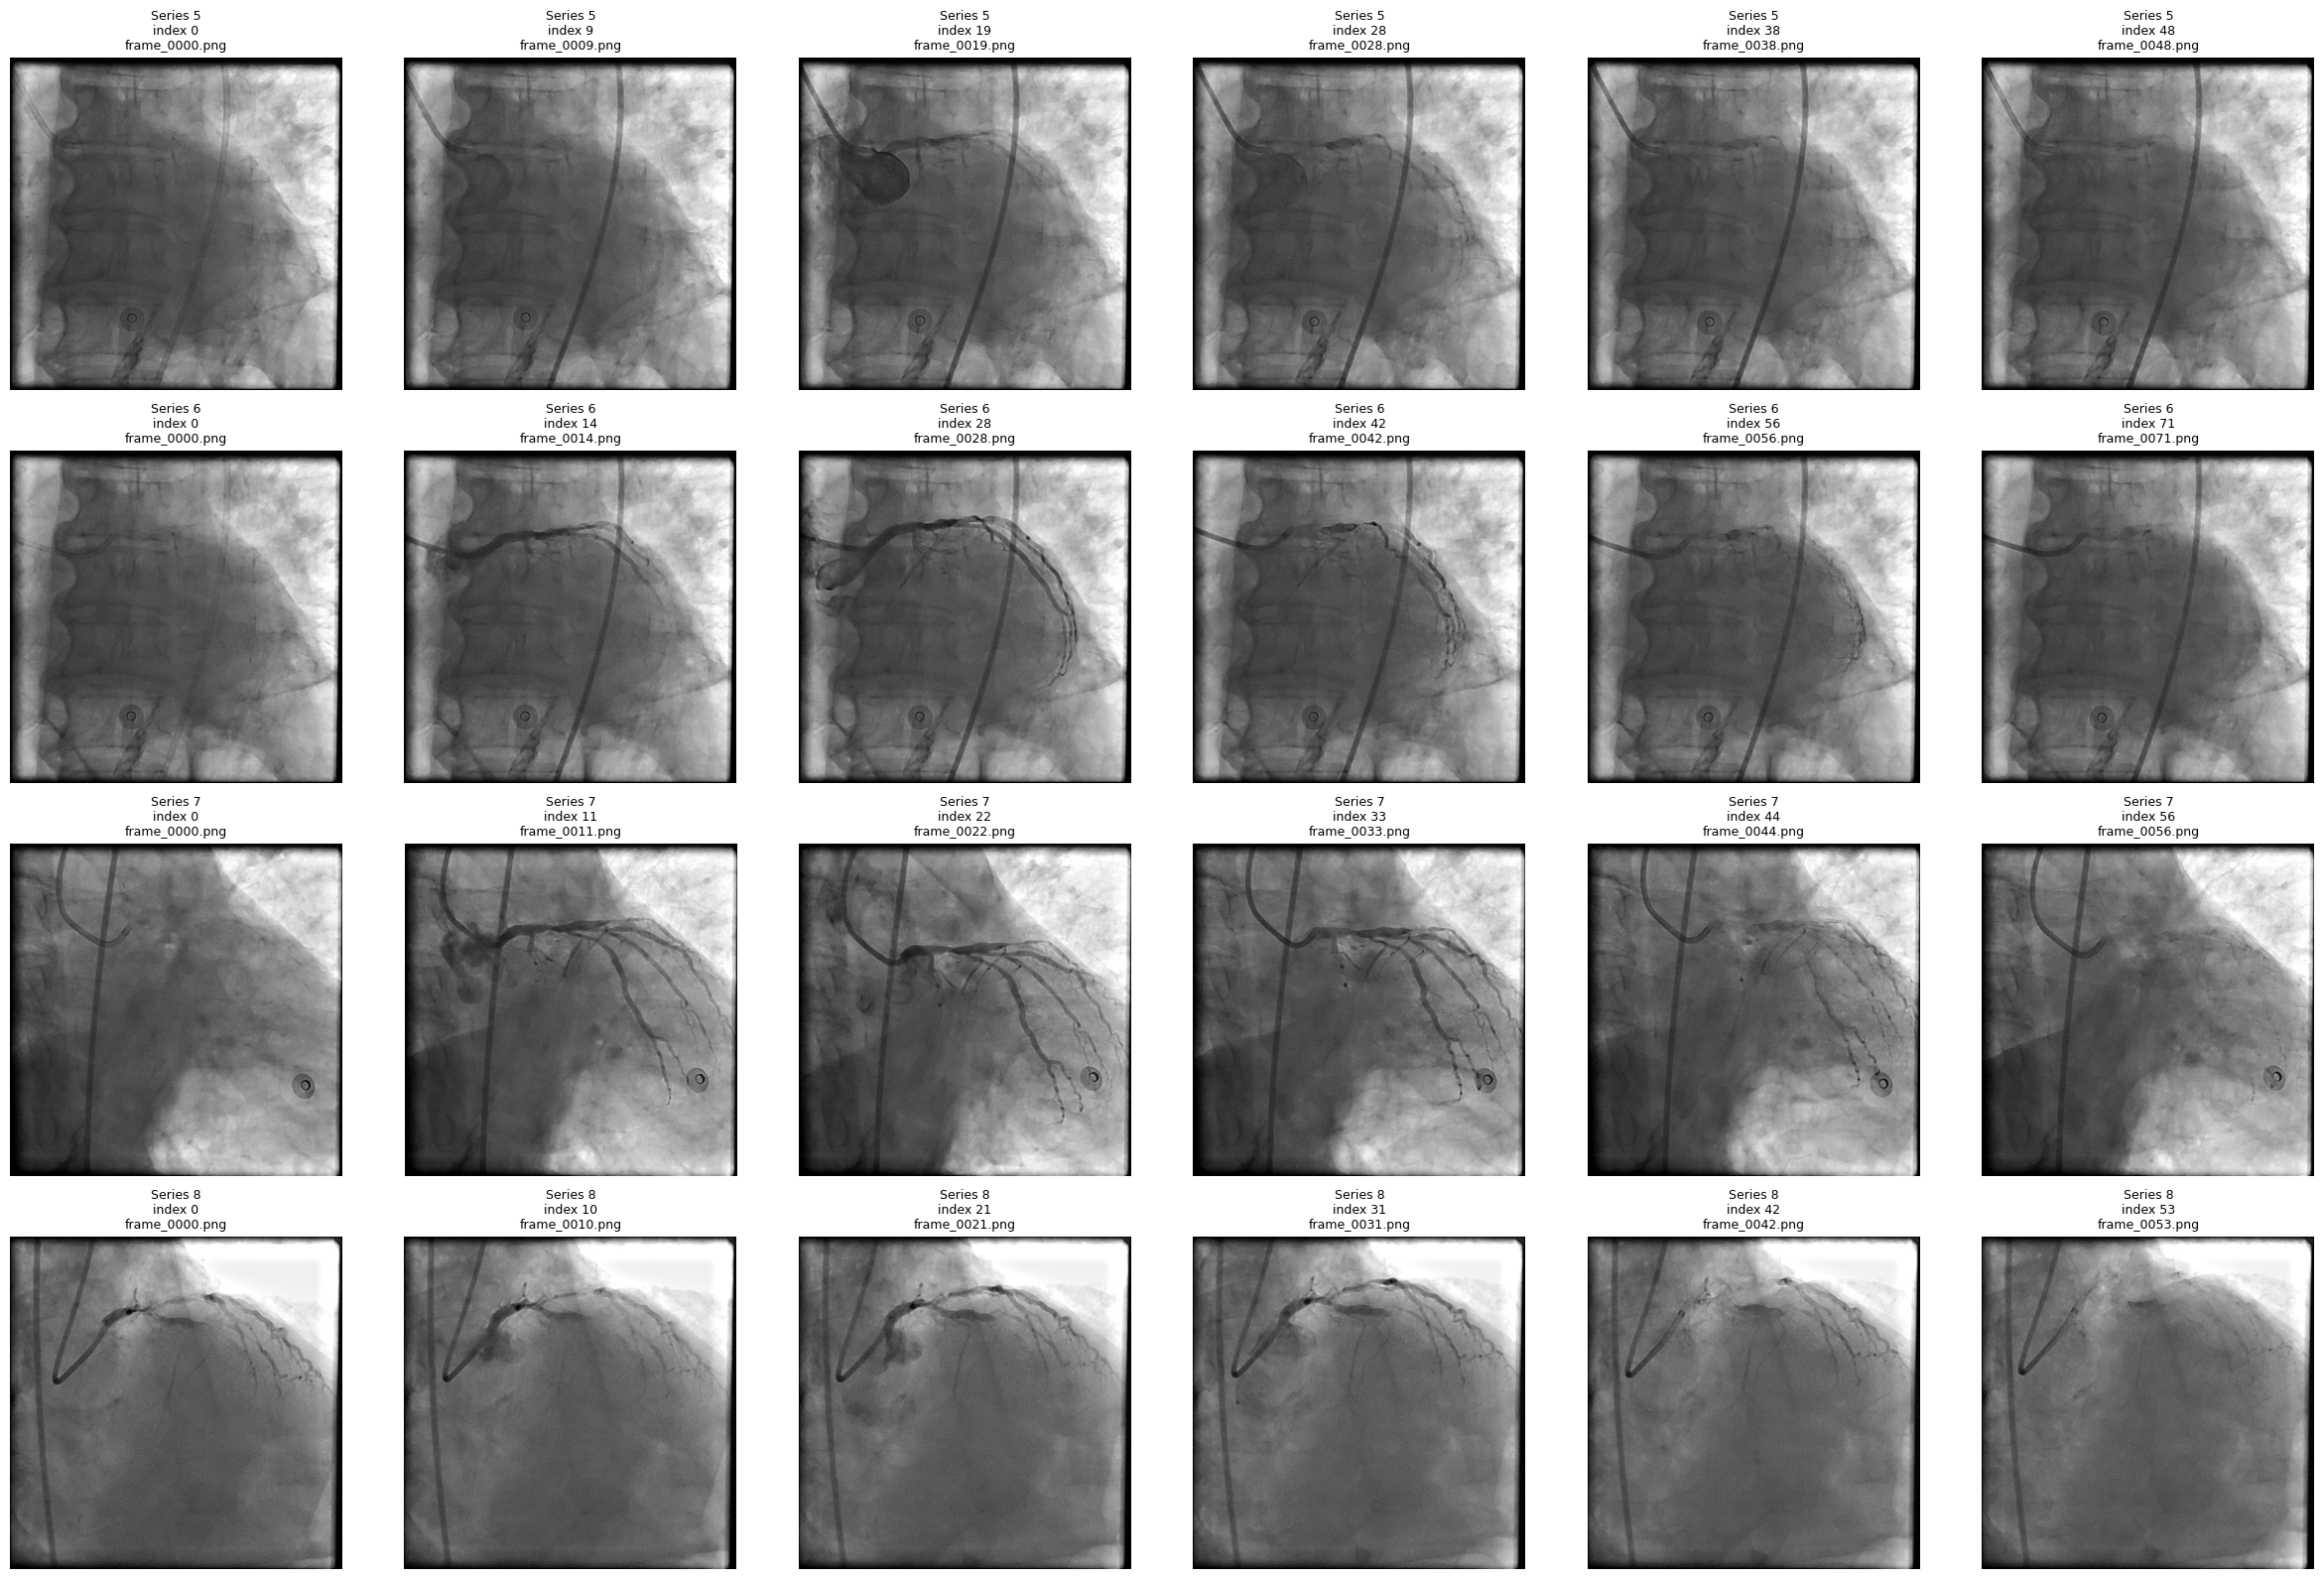

In [ ]:
#@title 05. Series 5~8 contact sheet 확인

FRAMES_PER_SERIES = 6

figure, axes = plt.subplots(
    len(series_frame_paths),
    FRAMES_PER_SERIES,
    figsize=(
        4 * FRAMES_PER_SERIES,
        4 * len(series_frame_paths),
    ),
)

axes = np.atleast_2d(axes)

for row_index, (
    candidate_series_id,
    frame_paths,
) in enumerate(
    series_frame_paths.items()
):

    # 초반부터 후반까지 균등하게 표시
    display_indices = np.linspace(
        0,
        len(frame_paths) - 1,
        FRAMES_PER_SERIES,
        dtype=int,
    )

    for column_index, frame_index in enumerate(
        display_indices
    ):
        path = frame_paths[
            int(frame_index)
        ]

        gray_image = cv2.imread(
            str(path),
            cv2.IMREAD_GRAYSCALE,
        )

        axes[
            row_index,
            column_index
        ].imshow(
            gray_image,
            cmap="gray",
        )

        axes[
            row_index,
            column_index
        ].set_title(
            f"Series {candidate_series_id}\n"
            f"index {frame_index}\n"
            f"{path.name}",
            fontsize=9,
        )

        axes[
            row_index,
            column_index
        ].axis("off")

plt.tight_layout()

VIEW_COMPARISON_PATH = (
    OUTPUT_DIR
    / "00_left_series_view_comparison.png"
)

plt.savefig(
    VIEW_COMPARISON_PATH,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [ ]:
# Series 7의 frame 22 한 장만 사용

selected_frame_paths = [
    next(
        path
        for path in series_frame_paths[7]
        if path.name == "frame_0022.png"
    )
]

print([
    str(path)
    for path in selected_frame_paths
])

['/content/AngioCAD_LCX_view_compare/AngioCAD_Dataset/6/7/frame_0022.png']


## mLLM 단계

mLLM에는 환자 ID와 협착 등급을 주지 않는다. 영상만 보고 먼저 LCA/RCA를
구분한 뒤, LM 분지에서 시작해 AV groove 방향으로 주행하는 LCX main trunk를
찾게 한다. LAD, diagonal, OM, catheter를 LCX로 오인하면 실패다.


In [ ]:
#@title 05. LCX grounding prompt와 JSON 검증 함수

import json
import math


SYSTEM_PROMPT = """
You are performing visual grounding on a single invasive left coronary
angiography frame for a research experiment.

Your only target is the LEFT CIRCUMFLEX CORONARY ARTERY MAIN TRUNK (LCX).

This task is localization only.
Do not estimate stenosis severity.
Do not use the supplied clinical label to guess the location.

IMPORTANT PREVIOUS FAILURE:
A previous attempt selected the guiding catheter or the LM ostium instead
of the LCX. You must explicitly identify and exclude the guiding catheter
before locating the LCX.

Analyze the image using the following anatomical sequence.

STEP 1 — Identify and exclude the guiding catheter

- The guiding catheter is usually darker and thicker than coronary vessels.
- It has a relatively uniform diameter.
- It enters from an image border and may form a large curve or U shape.
- It does not progressively divide into thin branches.
- The catheter and its tip are NOT the LCX.
- The first negative point must be placed on the guiding catheter.

STEP 2 — Identify the contrast-filled left coronary tree

- Coronary vessels are thinner than the guiding catheter.
- They form a connected, progressively branching tree.
- Ignore bones, spine, diaphragm, wires, circular markers and background.
- Confirm that this is a left coronary angiography frame.

STEP 3 — Locate the LM and its first major bifurcation

- Begin at the catheter tip or left coronary ostium.
- Follow the short left main coronary artery.
- Locate the first major division into LAD and LCX.
- The LM and the LM bifurcation are landmarks, not the final LCX target.

STEP 4 — Distinguish LAD, LCX and OM

- LAD generally continues toward the cardiac apex and gives diagonal
  or septal branches.
- LCX follows the atrioventricular groove and gives obtuse marginal branches.
- Do not rely only on left/right or up/down screen direction because
  angiographic projection changes apparent direction.
- Use vessel continuity and branching anatomy.
- An obtuse marginal branch is not the LCX main trunk.
- Do not select the LAD, a diagonal branch or a long descending branch.

STEP 5 — Trace the LCX main trunk with exactly three ordered points

Return exactly three LCX centerline points in this anatomical order:

1. proximal LCX:
   immediately after the LM bifurcation, not on the LM or catheter tip;

2. mid LCX:
   farther along the same connected LCX main trunk;

3. distal LCX:
   farther along the LCX main trunk in the atrioventricular groove,
   excluding OM branches.

The three points must trace one continuous vessel.
Do not cluster all three points around the LM bifurcation.
The normalized straight-line distance between the first and third points
must be at least 150 units.

Every LCX point must be:

- inside the visible contrast-filled LCX lumen;
- outside the guiding catheter;
- outside the LAD;
- outside OM side branches;
- anatomically downstream from the LM bifurcation.

STEP 6 — Construct the LCX bounding box

- Create a tight bounding box enclosing the traced LCX main trunk.
- The box must include all three LCX path points.
- The box must not mainly cover the catheter, LM, LAD or background.
- Do not create a small box containing only the catheter tip or LM ostium.
- Do not create an unnecessarily large box covering the whole coronary tree.

STEP 7 — Add negative points

Return exactly two negative points:

1. the first negative point must lie on the guiding catheter;
2. the second negative point must lie on the LAD or the strongest
   competing non-LCX coronary branch.

If the LCX main trunk cannot be followed confidently through three ordered
points, return lcx_status as "uncertain".

If the proposed LCX bounding box mainly contains the catheter, catheter tip,
LM ostium or LM bifurcation, return lcx_status as "uncertain".

For "uncertain" or "not_visible":

- best_image_index must be null;
- all LCX segment bounding boxes must be null;
- sam_prompt.bbox_norm_1000 must be null;
- sam_prompt.lcx_path_points_norm_1000 must be an empty list;
- sam_prompt.negative_points_norm_1000 must be an empty list.

COORDINATE RULES:

- All coordinates must be integers from 0 to 1000.
- The upper-left corner is (0, 0).
- The lower-right corner is (1000, 1000).
- A bounding box is [x1, y1, x2, y2].
- It must satisfy x1 < x2 and y1 < y2.

Return exactly one JSON object.
Do not include markdown, code fences or additional text.

Required JSON structure:

{
  "target": "LCX",

  "catheter": {
    "bbox_norm_1000": [x1, y1, x2, y2],
    "point_norm_1000": [x, y]
  },

  "landmarks": {
    "catheter_tip_norm_1000": [x, y],
    "lm_bifurcation_norm_1000": [x, y]
  },

  "coronary_system": "left|right|uncertain",
  "lcx_status": "visible|not_visible|uncertain",
  "best_image_index": 0,

  "segments": {
    "prox_lcx": {
      "visibility": "visible|not_visible|uncertain",
      "bbox_norm_1000": [x1, y1, x2, y2]
    },
    "mid_lcx": {
      "visibility": "visible|not_visible|uncertain",
      "bbox_norm_1000": [x1, y1, x2, y2]
    },
    "dist_lcx": {
      "visibility": "visible|not_visible|uncertain",
      "bbox_norm_1000": [x1, y1, x2, y2]
    }
  },

  "sam_prompt": {
    "text": "left circumflex coronary artery main trunk",

    "bbox_norm_1000": [x1, y1, x2, y2],

    "lcx_path_points_norm_1000": [
      [x_prox, y_prox],
      [x_mid, y_mid],
      [x_dist, y_dist]
    ],

    "negative_points_norm_1000": [
      [x_catheter, y_catheter],
      [x_lad, y_lad]
    ]
  },

  "self_check": {
    "bbox_mainly_contains_catheter": false,
    "positive_point_on_catheter": false,
    "points_clustered_near_lm": false,
    "lcx_connected_to_lm_bifurcation": true,
    "lad_excluded": true,
    "om_branches_excluded": true
  },

  "confidence": 0.0,
  "rationale": "Short anatomical explanation only."
}
"""


USER_PROMPT = """
Analyze the supplied single left coronary angiography frame.

This is a correction attempt because a previous result selected the
guiding catheter or the LM ostium instead of the LCX.

Perform the analysis in this order:

1. identify the thick guiding catheter;
2. locate the catheter tip and left coronary ostium;
3. follow the short LM to its first major bifurcation;
4. distinguish LAD from LCX using vessel continuity and branching;
5. trace the LCX main trunk using proximal, mid and distal points;
6. construct a tight LCX box enclosing those three points;
7. place negative points on the catheter and LAD.

Do not place all LCX points around the LM bifurcation.
If three ordered LCX points cannot be traced confidently, return
lcx_status as "uncertain".

Return only the required JSON object.
"""


def extract_json(text):
    """모델 출력에서 첫 JSON 객체를 추출한다."""

    start = text.find("{")
    end = text.rfind("}")

    assert start >= 0 and end > start, (
        "mLLM 출력에서 JSON object를 찾지 못했습니다."
    )

    json_text = text[start:end + 1]
    return json.loads(json_text)


def validate_point(point, allow_none=False):
    """[x, y] normalized point 형식을 검사한다."""

    if point is None:
        assert allow_none, "point에 null을 사용할 수 없습니다."
        return

    assert isinstance(point, list), (
        f"point는 list여야 합니다: {point}"
    )
    assert len(point) == 2, (
        f"point 길이는 2여야 합니다: {point}"
    )
    assert all(
        isinstance(value, int) and 0 <= value <= 1000
        for value in point
    ), f"point 좌표는 0~1000의 정수여야 합니다: {point}"


def validate_box(box, allow_none=False):
    """[x1, y1, x2, y2] normalized box 형식을 검사한다."""

    if box is None:
        assert allow_none, "bbox에 null을 사용할 수 없습니다."
        return

    assert isinstance(box, list), (
        f"bbox는 list여야 합니다: {box}"
    )
    assert len(box) == 4, (
        f"bbox 길이는 4여야 합니다: {box}"
    )
    assert all(
        isinstance(value, int) and 0 <= value <= 1000
        for value in box
    ), f"bbox 좌표는 0~1000의 정수여야 합니다: {box}"

    x1, y1, x2, y2 = box

    assert x1 < x2 and y1 < y2, (
        f"잘못된 bbox 좌표 순서입니다: {box}"
    )


def point_inside_box(point, box):
    """point가 bbox 내부에 있는지 확인한다."""

    x, y = point
    x1, y1, x2, y2 = box

    return x1 <= x <= x2 and y1 <= y <= y2


def validate_grounding(data, image_count):
    """
    mLLM JSON의 구조와 좌표를 검사한다.

    해부학적으로 올바른 위치인지는 07번 셀의 Gate와
    시각화 결과를 통해 추가로 검사한다.
    """

    assert isinstance(data, dict), (
        "grounding 결과는 dictionary여야 합니다."
    )

    assert data.get("target") == "LCX"

    assert data.get("coronary_system") in {
        "left",
        "right",
        "uncertain",
    }

    assert data.get("lcx_status") in {
        "visible",
        "not_visible",
        "uncertain",
    }

    confidence = float(data.get("confidence", -1))

    assert 0.0 <= confidence <= 1.0, (
        f"confidence 범위 오류: {confidence}"
    )

    # catheter
    catheter = data.get("catheter", {})

    validate_box(
        catheter.get("bbox_norm_1000"),
        allow_none=True,
    )
    validate_point(
        catheter.get("point_norm_1000"),
        allow_none=True,
    )

    # landmarks
    landmarks = data.get("landmarks", {})

    validate_point(
        landmarks.get("catheter_tip_norm_1000"),
        allow_none=True,
    )
    validate_point(
        landmarks.get("lm_bifurcation_norm_1000"),
        allow_none=True,
    )

    # LCX segments
    segments = data.get("segments", {})

    for segment_name in (
        "prox_lcx",
        "mid_lcx",
        "dist_lcx",
    ):
        assert segment_name in segments, (
            f"segments에 {segment_name}이 없습니다."
        )

        segment = segments[segment_name]

        assert segment.get("visibility") in {
            "visible",
            "not_visible",
            "uncertain",
        }

        validate_box(
            segment.get("bbox_norm_1000"),
            allow_none=True,
        )

    # SAM prompt
    sam_prompt = data.get("sam_prompt", {})

    assert sam_prompt.get("text") == (
        "left circumflex coronary artery main trunk"
    )

    lcx_box = sam_prompt.get("bbox_norm_1000")
    lcx_points = sam_prompt.get(
        "lcx_path_points_norm_1000",
        [],
    )
    negative_points = sam_prompt.get(
        "negative_points_norm_1000",
        [],
    )

    assert isinstance(lcx_points, list)
    assert isinstance(negative_points, list)

    # best image
    best_image_index = data.get("best_image_index")

    if best_image_index is not None:
        assert isinstance(best_image_index, int)
        assert 0 <= best_image_index < image_count

    if data["lcx_status"] == "visible":
        assert data["coronary_system"] == "left", (
            "LCX visible인데 coronary_system이 left가 아닙니다."
        )

        assert best_image_index is not None, (
            "LCX visible이면 best_image_index가 필요합니다."
        )

        validate_box(lcx_box)

        assert len(lcx_points) == 3, (
            "LCX visible이면 proximal/mid/distal 점이 "
            "정확히 3개 필요합니다."
        )

        for point in lcx_points:
            validate_point(point)

            assert point_inside_box(point, lcx_box), (
                f"LCX path point가 bbox 밖에 있습니다: {point}"
            )

        assert len(negative_points) == 2, (
            "negative point는 catheter와 LAD에 "
            "각각 하나씩 총 2개가 필요합니다."
        )

        for point in negative_points:
            validate_point(point)

    else:
        assert best_image_index is None, (
            "LCX가 visible이 아니면 "
            "best_image_index는 null이어야 합니다."
        )

        assert lcx_box is None, (
            "LCX가 visible이 아니면 bbox는 null이어야 합니다."
        )

        assert len(lcx_points) == 0, (
            "LCX가 visible이 아니면 path points는 비워야 합니다."
        )

        assert len(negative_points) == 0, (
            "LCX가 visible이 아니면 negative points는 비워야 합니다."
        )

    # self-check 구조 검사
    self_check = data.get("self_check", {})

    required_self_checks = (
        "bbox_mainly_contains_catheter",
        "positive_point_on_catheter",
        "points_clustered_near_lm",
        "lcx_connected_to_lm_bifurcation",
        "lad_excluded",
        "om_branches_excluded",
    )

    for check_name in required_self_checks:
        assert isinstance(
            self_check.get(check_name),
            bool,
        ), f"self_check.{check_name}은 bool이어야 합니다."

    return data


def calculate_lcx_path_distance(lcx_points):
    """첫 LCX 점과 마지막 LCX 점 사이 normalized 거리를 계산한다."""

    assert len(lcx_points) == 3

    start_point = lcx_points[0]
    end_point = lcx_points[-1]

    return math.dist(start_point, end_point)


def norm_box_to_pixels(box, width, height):
    """0~1000 normalized bbox를 실제 이미지 pixel bbox로 변환한다."""

    x1 = max(
        0,
        min(
            width - 1,
            round(box[0] * width / 1000),
        ),
    )
    y1 = max(
        0,
        min(
            height - 1,
            round(box[1] * height / 1000),
        ),
    )
    x2 = max(
        x1 + 1,
        min(
            width,
            round(box[2] * width / 1000),
        ),
    )
    y2 = max(
        y1 + 1,
        min(
            height,
            round(box[3] * height / 1000),
        ),
    )

    return x1, y1, x2, y2


print("✅ LCX path 기반 prompt와 validation 준비 완료")

✅ LCX path 기반 prompt와 validation 준비 완료


In [ ]:
# @title
%pip install \
    --force-reinstall \
    --no-cache-dir \
    "numpy==2.1.3" \
    "scipy==1.15.3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 8.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 306.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 259.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 335.6 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
  Attempting uninstall: scipy
    Found existing installation: scipy 1.15.3
    Uninstalling scipy-1.15.3:
      Successfully uninstalled scipy-1.15.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sam3 0.1.0 requires numpy==1.26, but you have numpy 2.1.3 which is incompatible.


In [ ]:
# @title
import sys
import numpy
import scipy
import transformers

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("Transformers:", transformers.__version__)

assert numpy.__version__ == "2.1.3"
assert scipy.__version__ == "1.15.3"

print("✅ NumPy/SciPy ABI 정상")

Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
NumPy: 2.1.3
SciPy: 1.15.3
Transformers: 5.16.1
✅ NumPy/SciPy ABI 정상


In [ ]:
#@title 06. Qwen2.5-VL 7B(4-bit)로 실제 LCX grounding 실행

import copy
import gc
import json
import time
import torch

from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen2_5_VLForConditionalGeneration,
)
from qwen_vl_utils import process_vision_info


# ---------------------------------------------------------
# 1. 실행 환경 검사
# ---------------------------------------------------------

assert torch.cuda.is_available(), (
    "GPU를 찾지 못했습니다. "
    "Colab에서 GPU 런타임을 선택하세요."
)

assert "SYSTEM_PROMPT" in globals(), (
    "먼저 05번 셀을 실행하세요."
)

assert "USER_PROMPT" in globals(), (
    "먼저 05번 셀을 실행하세요."
)

assert "selected_frame_paths" in globals(), (
    "먼저 프레임 선택 셀을 실행하세요."
)

assert len(selected_frame_paths) == 1, (
    "현재 프롬프트는 단일 프레임용입니다. "
    "selected_frame_paths에는 이미지 1개만 넣으세요."
)

assert selected_frame_paths[0].exists(), (
    f"선택 이미지가 존재하지 않습니다: "
    f"{selected_frame_paths[0]}"
)

assert "OUTPUT_DIR" in globals(), (
    "OUTPUT_DIR이 정의되지 않았습니다."
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ---------------------------------------------------------
# 2. mLLM 출력 정규화 함수
# ---------------------------------------------------------

def normalize_grounding_output(data):
    """
    Qwen이 null 대신 []를 출력하는 경우처럼
    표현상의 차이만 검증 규칙에 맞게 정규화한다.

    visible/uncertain 같은 모델의 의미 판단은 변경하지 않는다.
    """

    normalized = copy.deepcopy(data)

    status = normalized.get(
        "lcx_status",
        "uncertain",
    )

    # LCX segment의 빈 bbox []를 None으로 변경
    segments = normalized.get(
        "segments",
        {},
    )

    for segment_name in (
        "prox_lcx",
        "mid_lcx",
        "dist_lcx",
    ):
        segment = segments.get(
            segment_name,
            {},
        )

        if segment.get("bbox_norm_1000") == []:
            segment["bbox_norm_1000"] = None

    # catheter와 landmark에서도 빈 배열이 나오면 None 처리
    catheter = normalized.get(
        "catheter",
        {},
    )

    if catheter.get("bbox_norm_1000") == []:
        catheter["bbox_norm_1000"] = None

    if catheter.get("point_norm_1000") == []:
        catheter["point_norm_1000"] = None

    landmarks = normalized.get(
        "landmarks",
        {},
    )

    if landmarks.get("catheter_tip_norm_1000") == []:
        landmarks["catheter_tip_norm_1000"] = None

    if landmarks.get("lm_bifurcation_norm_1000") == []:
        landmarks["lm_bifurcation_norm_1000"] = None

    # SAM prompt 정규화
    sam_prompt = normalized.get(
        "sam_prompt",
        {},
    )

    if sam_prompt.get("bbox_norm_1000") == []:
        sam_prompt["bbox_norm_1000"] = None

    if sam_prompt.get(
        "lcx_path_points_norm_1000"
    ) is None:
        sam_prompt[
            "lcx_path_points_norm_1000"
        ] = []

    if sam_prompt.get(
        "negative_points_norm_1000"
    ) is None:
        sam_prompt[
            "negative_points_norm_1000"
        ] = []

    # visible이 아니면 SAM에 전달할 프롬프트를 제거
    if status != "visible":
        normalized["best_image_index"] = None

        sam_prompt["bbox_norm_1000"] = None
        sam_prompt[
            "lcx_path_points_norm_1000"
        ] = []
        sam_prompt[
            "negative_points_norm_1000"
        ] = []

    return normalized


# ---------------------------------------------------------
# 3. 셀 재실행 시 기존 GPU 메모리 정리
# ---------------------------------------------------------

variables_to_clear = [
    "mllm",
    "mllm_processor",
    "model_inputs",
    "generated_ids",
    "image_inputs",
    "video_inputs",
]

for variable_name in variables_to_clear:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()
torch.cuda.empty_cache()


# ---------------------------------------------------------
# 4. Qwen2.5-VL 7B 4-bit 모델 로드
# ---------------------------------------------------------

MLLM_MODEL_ID = (
    "Qwen/Qwen2.5-VL-7B-Instruct"
)

COMPUTE_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

print(
    "GPU:",
    torch.cuda.get_device_name(0),
)

print(
    "4-bit compute dtype:",
    COMPUTE_DTYPE,
)

print(
    "선택 이미지:",
    selected_frame_paths[0],
)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
)

mllm = (
    Qwen2_5_VLForConditionalGeneration
    .from_pretrained(
        MLLM_MODEL_ID,
        quantization_config=quant_config,
        device_map="auto",
        low_cpu_mem_usage=True,
    )
)

mllm.eval()

mllm_processor = AutoProcessor.from_pretrained(
    MLLM_MODEL_ID,
    min_pixels=256 * 28 * 28,
    max_pixels=1024 * 28 * 28,
)

print("✅ Qwen2.5-VL 모델 로드 완료")


# ---------------------------------------------------------
# 5. 이미지와 프롬프트 구성
# ---------------------------------------------------------

selected_image_uri = (
    selected_frame_paths[0]
    .resolve()
    .as_uri()
)

user_content = [
    {
        "type": "image",
        "image": selected_image_uri,
    },
    {
        "type": "text",
        "text": USER_PROMPT,
    },
]

messages = [
    {
        "role": "system",
        "content": SYSTEM_PROMPT,
    },
    {
        "role": "user",
        "content": user_content,
    },
]

prompt_text = (
    mllm_processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
)

image_inputs, video_inputs = (
    process_vision_info(messages)
)

model_inputs = mllm_processor(
    text=[prompt_text],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt",
)

model_inputs = model_inputs.to(
    mllm.device
)


# ---------------------------------------------------------
# 6. LCX grounding 추론
# ---------------------------------------------------------

start_time = time.time()

with torch.inference_mode():
    generated_ids = mllm.generate(
        **model_inputs,
        max_new_tokens=1200,
        do_sample=False,
        use_cache=True,
    )

input_token_length = (
    model_inputs.input_ids.shape[1]
)

generated_ids = generated_ids[
    :,
    input_token_length:
]

raw_mllm_response = (
    mllm_processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]
)

mllm_seconds = (
    time.time() - start_time
)


# ---------------------------------------------------------
# 7. 원본 응답 출력 및 저장
# ---------------------------------------------------------

MLLM_RAW_RESPONSE_PATH = (
    OUTPUT_DIR
    / "02_lcx_mllm_raw_response.txt"
)

with open(
    MLLM_RAW_RESPONSE_PATH,
    "w",
    encoding="utf-8",
) as file:
    file.write(raw_mllm_response)

print("\n=== Raw mLLM response ===")
print(raw_mllm_response)
print("=========================\n")

print(
    "원본 응답 저장:",
    MLLM_RAW_RESPONSE_PATH,
)


# ---------------------------------------------------------
# 8. JSON 추출, 정규화 및 검증
# ---------------------------------------------------------

try:
    raw_parsed_grounding = extract_json(
        raw_mllm_response
    )

    normalized_grounding = (
        normalize_grounding_output(
            raw_parsed_grounding
        )
    )

    grounding = validate_grounding(
        normalized_grounding,
        image_count=len(
            selected_frame_paths
        ),
    )

except Exception as error:
    print(
        "❌ mLLM JSON 추출 또는 검증 실패"
    )
    print(
        "오류:",
        repr(error),
    )
    print(
        "위의 Raw mLLM response를 확인하세요."
    )
    raise


# ---------------------------------------------------------
# 9. 원본 JSON과 정규화된 JSON 저장
# ---------------------------------------------------------

MLLM_RESULT_PATH = (
    OUTPUT_DIR
    / "02_lcx_mllm_grounding.json"
)

result_to_save = {
    "model": MLLM_MODEL_ID,
    "seconds": mllm_seconds,
    "selected_frames": [
        str(path)
        for path in selected_frame_paths
    ],

    # Qwen이 실제로 출력한 내용
    "raw_parsed_grounding": (
        raw_parsed_grounding
    ),

    # 표현만 정규화한 결과
    "grounding": grounding,
}

with open(
    MLLM_RESULT_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        result_to_save,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ---------------------------------------------------------
# 10. 최종 결과 출력
# ---------------------------------------------------------

print(
    "✅ mLLM JSON 추출 및 검증 완료"
)

print(
    json.dumps(
        grounding,
        indent=2,
        ensure_ascii=False,
    )
)

print(
    "mLLM seconds:",
    round(mllm_seconds, 2),
)

print(
    "검증 결과 저장:",
    MLLM_RESULT_PATH,
)

if grounding["lcx_status"] != "visible":
    print()
    print(
        "⚠️ LCX status:",
        grounding["lcx_status"],
    )
    print(
        "LCX를 찾지 못했으므로 "
        "Medical-SAM3 box 추론에 전달하지 않습니다."
    )

GPU: NVIDIA L4
4-bit compute dtype: torch.bfloat16
선택 이미지: /content/AngioCAD_LCX_view_compare/AngioCAD_Dataset/6/7/frame_0022.png


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

✅ Qwen2.5-VL 모델 로드 완료

=== Raw mLLM response ===
```json
{
  "target": "LCX",

  "catheter": {
    "bbox_norm_1000": [1, 1, 198, 558],
    "point_norm_1000": [198, 558]
  },

  "landmarks": {
    "catheter_tip_norm_1000": [198, 558],
    "lm_bifurcation_norm_1000": [198, 558]
  },

  "coronary_system": "left",
  "lcx_status": "uncertain",
  "best_image_index": 0,

  "segments": {
    "prox_lcx": {
      "visibility": "not_visible",
      "bbox_norm_1000": []
    },
    "mid_lcx": {
      "visibility": "not_visible",
      "bbox_norm_1000": []
    },
    "dist_lcx": {
      "visibility": "not_visible",
      "bbox_norm_1000": []
    }
  },

  "sam_prompt": {
    "text": "left circumflex coronary artery main trunk",

    "bbox_norm_1000": [],
    "lcx_path_points_norm_1000": [],
    "negative_points_norm_1000": [
      [198, 558],
      [198, 558]
    ]
  },

  "self_check": {
    "bbox_mainly_contains_catheter": true,
    "positive_point_on_catheter": true,
    "points_clustered_near_lm

선택 이미지: /content/AngioCAD_LCX_view_compare/AngioCAD_Dataset/6/7/frame_0033.png


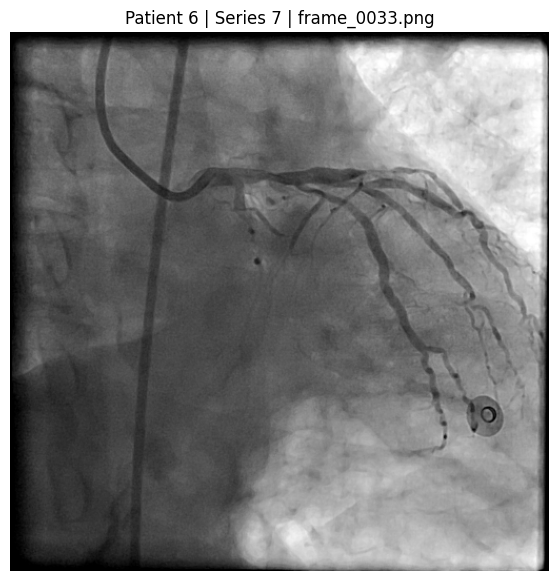

이번 결과 저장 폴더: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/dca1_results/medicalsam3_mllm_lcx/patient_006_series_7_frame_0033

=== Raw mLLM response ===
```json
{
  "target": "LCX",

  "catheter": {
    "bbox_norm_1000": [100, 0, 200, 500],
    "point_norm_1000": [150, 250]
  },

  "landmarks": {
    "catheter_tip_norm_1000": [150, 250],
    "lm_bifurcation_norm_1000": [250, 150]
  },

  "coronary_system": "left",
  "lcx_status": "visible",
  "best_image_index": 0,

  "segments": {
    "prox_lcx": {
      "visibility": "visible",
      "bbox_norm_1000": [250, 150, 350, 250]
    },
    "mid_lcx": {
      "visibility": "visible",
      "bbox_norm_1000": [300, 200, 400, 300]
    },
    "dist_lcx": {
      "visibility": "visible",
      "bbox_norm_1000": [350, 250, 450, 350]
    }
  },

  "sam_prompt": {
    "text": "left circumflex coronary artery main trunk",

    "bbox_norm_1000": [250, 150, 450, 350],

    "lcx_path_points_norm_1000": [
      [250, 150],
      [350, 250],
   

In [ ]:
#@title 06-B. 다른 프레임에서 LCX grounding 재실험

import json
import time
import torch
import matplotlib.pyplot as plt

from PIL import Image
from qwen_vl_utils import process_vision_info


# ---------------------------------------------------------
# 1. 재실험할 프레임 선택
# ---------------------------------------------------------

NEXT_SERIES_ID = 7
NEXT_FRAME_NAME = "frame_0033.png"

assert "series_frame_paths" in globals(), (
    "series_frame_paths가 없습니다. "
    "먼저 프레임 추출/선택 셀을 실행하세요."
)

assert NEXT_SERIES_ID in series_frame_paths, (
    f"Series {NEXT_SERIES_ID}를 찾을 수 없습니다."
)

frame_candidates = [
    path
    for path in series_frame_paths[NEXT_SERIES_ID]
    if path.name == NEXT_FRAME_NAME
]

assert len(frame_candidates) == 1, (
    f"Series {NEXT_SERIES_ID}에서 "
    f"{NEXT_FRAME_NAME}을 정확히 하나 찾지 못했습니다. "
    f"검색 결과: {frame_candidates}"
)

selected_frame_paths = [
    frame_candidates[0]
]

selected_image_path = selected_frame_paths[0]

print("선택 이미지:", selected_image_path)


# ---------------------------------------------------------
# 2. 선택 이미지 확인
# ---------------------------------------------------------

selected_image = Image.open(
    selected_image_path
).convert("RGB")

plt.figure(figsize=(7, 7))
plt.imshow(selected_image)
plt.title(
    f"Patient 6 | Series {NEXT_SERIES_ID} | "
    f"{NEXT_FRAME_NAME}"
)
plt.axis("off")
plt.show()


# ---------------------------------------------------------
# 3. 기존 Qwen 모델 및 함수 확인
# ---------------------------------------------------------

assert "mllm" in globals(), (
    "Qwen 모델이 메모리에 없습니다. "
    "먼저 기존 06번 셀을 실행하세요."
)

assert "mllm_processor" in globals(), (
    "mllm_processor가 없습니다."
)

assert "SYSTEM_PROMPT" in globals()
assert "USER_PROMPT" in globals()
assert "extract_json" in globals()
assert "normalize_grounding_output" in globals()
assert "validate_grounding" in globals()

mllm.eval()


# ---------------------------------------------------------
# 4. 이번 실험의 저장 폴더 생성
# ---------------------------------------------------------

PREVIOUS_OUTPUT_DIR = OUTPUT_DIR

NEXT_OUTPUT_DIR = (
    PREVIOUS_OUTPUT_DIR.parent
    / (
        f"patient_006_series_{NEXT_SERIES_ID}_"
        f"{selected_image_path.stem}"
    )
)

NEXT_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("이번 결과 저장 폴더:", NEXT_OUTPUT_DIR)


# ---------------------------------------------------------
# 5. 이미지와 프롬프트 구성
# ---------------------------------------------------------

selected_image_uri = (
    selected_image_path
    .resolve()
    .as_uri()
)

user_content = [
    {
        "type": "image",
        "image": selected_image_uri,
    },
    {
        "type": "text",
        "text": USER_PROMPT,
    },
]

messages = [
    {
        "role": "system",
        "content": SYSTEM_PROMPT,
    },
    {
        "role": "user",
        "content": user_content,
    },
]

prompt_text = (
    mllm_processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
)

image_inputs, video_inputs = (
    process_vision_info(messages)
)

model_inputs = mllm_processor(
    text=[prompt_text],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt",
)

model_inputs = model_inputs.to(
    mllm.device
)


# ---------------------------------------------------------
# 6. Qwen LCX grounding 재추론
# ---------------------------------------------------------

start_time = time.time()

with torch.inference_mode():
    generated_ids = mllm.generate(
        **model_inputs,
        max_new_tokens=1200,
        do_sample=False,
        use_cache=True,
    )

input_token_length = (
    model_inputs.input_ids.shape[1]
)

generated_ids = generated_ids[
    :,
    input_token_length:
]

raw_mllm_response = (
    mllm_processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]
)

mllm_seconds = (
    time.time() - start_time
)


# ---------------------------------------------------------
# 7. 원본 응답 출력 및 저장
# ---------------------------------------------------------

MLLM_RAW_RESPONSE_PATH = (
    NEXT_OUTPUT_DIR
    / "02_lcx_mllm_raw_response.txt"
)

with open(
    MLLM_RAW_RESPONSE_PATH,
    "w",
    encoding="utf-8",
) as file:
    file.write(raw_mllm_response)

print("\n=== Raw mLLM response ===")
print(raw_mllm_response)
print("=========================\n")


# ---------------------------------------------------------
# 8. JSON 추출, 정규화 및 검증
# ---------------------------------------------------------

try:
    raw_parsed_grounding = extract_json(
        raw_mllm_response
    )

    normalized_grounding = (
        normalize_grounding_output(
            raw_parsed_grounding
        )
    )

    grounding = validate_grounding(
        normalized_grounding,
        image_count=1,
    )

except Exception as error:
    print("❌ JSON 추출 또는 검증 실패")
    print("오류:", repr(error))
    print(
        "원본 응답:",
        MLLM_RAW_RESPONSE_PATH,
    )
    raise


# ---------------------------------------------------------
# 9. 결과 저장
# ---------------------------------------------------------

MLLM_RESULT_PATH = (
    NEXT_OUTPUT_DIR
    / "02_lcx_mllm_grounding.json"
)

result_to_save = {
    "patient_id": 6,
    "series_id": NEXT_SERIES_ID,
    "frame_name": NEXT_FRAME_NAME,
    "model": MLLM_MODEL_ID,
    "seconds": mllm_seconds,
    "selected_frames": [
        str(path)
        for path in selected_frame_paths
    ],
    "raw_parsed_grounding": (
        raw_parsed_grounding
    ),
    "grounding": grounding,
}

with open(
    MLLM_RESULT_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        result_to_save,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ---------------------------------------------------------
# 10. 결과 판정
# ---------------------------------------------------------

print("✅ 다른 프레임 추론 완료")

print(
    json.dumps(
        grounding,
        indent=2,
        ensure_ascii=False,
    )
)

print(
    "mLLM seconds:",
    round(mllm_seconds, 2),
)

print(
    "결과 저장:",
    MLLM_RESULT_PATH,
)

print()
print(
    "LCX status:",
    grounding["lcx_status"],
)

if grounding["lcx_status"] == "visible":
    print(
        "✅ LCX 후보를 반환했습니다."
    )
    print(
        "바로 SAM에 전달하지 말고 "
        "07번 셀에서 box와 점 3개를 확인하세요."
    )

else:
    print(
        "⚠️ 이 프레임에서도 LCX를 찾지 못했습니다."
    )
    print(
        "Medical-SAM3에는 전달하지 않습니다."
    )

=== mLLM grounding gate ===
✅ lcx_visible
✅ valid_image_index
✅ valid_lcx_box
✅ valid_catheter_box
✅ three_lcx_path_points_exist
✅ lcx_points_inside_box
✅ lcx_points_not_clustered
✅ two_negative_points_exist
✅ model_reports_catheter_excluded
✅ model_reports_positive_not_on_catheter
✅ model_reports_points_not_clustered
✅ model_reports_connected_to_lm
✅ model_reports_lad_excluded
✅ model_reports_om_excluded

Catheter box: [100, 0, 200, 500]
LCX box: [250, 150, 450, 350]
LCX path points: [[250, 150], [350, 250], [450, 350]]
Negative points: [[150, 250], [250, 250]]
LCX start-end distance: 282.84


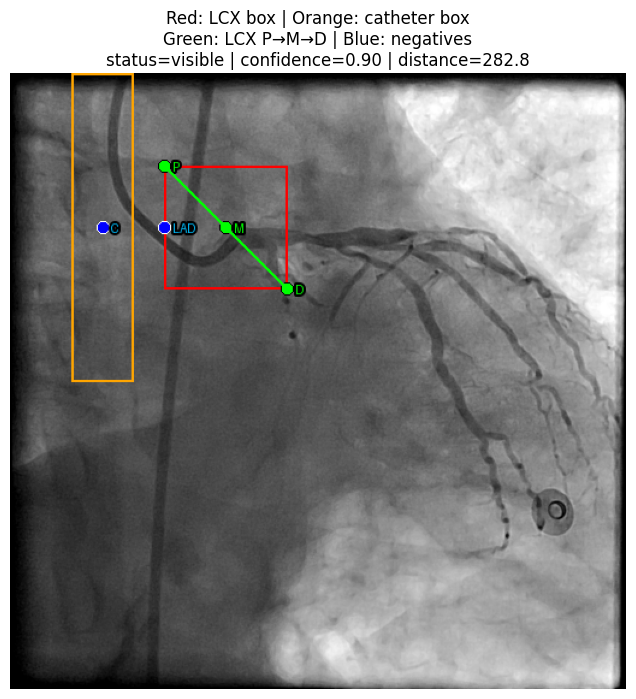

선택 영상: /content/AngioCAD_LCX_view_compare/AngioCAD_Dataset/6/7/frame_0033.png
Medical-SAM3 LCX pixel bbox: (128, 77, 230, 179)
Catheter pixel bbox: (51, 0, 102, 256)
Preview 저장: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/dca1_results/medicalsam3_mllm_lcx/patient_006_series_7_frame_0033/03_lcx_mllm_prompt_preview.png
✅ Gate 통과: Medical-SAM3에 전달할 수 있습니다.


In [ ]:
#@title 07. mLLM LCX grounding Gate 및 경로점 시각화

import math
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw


# ---------------------------------------------------------
# 1. 필요한 결과 확인
# ---------------------------------------------------------

assert "grounding" in globals(), (
    "먼저 06번 또는 06-B 셀을 실행하세요."
)

assert "selected_frame_paths" in globals()
assert len(selected_frame_paths) == 1

sam_prompt = grounding.get(
    "sam_prompt",
    {},
)

self_check = grounding.get(
    "self_check",
    {},
)

lcx_status = grounding.get(
    "lcx_status",
    "uncertain",
)

best_image_index = grounding.get(
    "best_image_index"
)

catheter_box = grounding.get(
    "catheter",
    {},
).get(
    "bbox_norm_1000"
)

lcx_box = sam_prompt.get(
    "bbox_norm_1000"
)

# 새 프롬프트에서 사용하는 실제 LCX 점
lcx_path_points = sam_prompt.get(
    "lcx_path_points_norm_1000",
    [],
)

negative_points = sam_prompt.get(
    "negative_points_norm_1000",
    [],
)


# ---------------------------------------------------------
# 2. 좌표 검사 함수
# ---------------------------------------------------------

def is_valid_norm_point(point):
    return (
        isinstance(point, list)
        and len(point) == 2
        and all(
            isinstance(value, int)
            and 0 <= value <= 1000
            for value in point
        )
    )


def is_valid_norm_box(box):
    return (
        isinstance(box, list)
        and len(box) == 4
        and all(
            isinstance(value, int)
            and 0 <= value <= 1000
            for value in box
        )
        and box[0] < box[2]
        and box[1] < box[3]
    )


def point_inside_norm_box(point, box):
    if not (
        is_valid_norm_point(point)
        and is_valid_norm_box(box)
    ):
        return False

    x, y = point
    x1, y1, x2, y2 = box

    return (
        x1 <= x <= x2
        and y1 <= y <= y2
    )


def norm_point_to_pixels(
    point,
    width,
    height,
):
    x = round(
        point[0] * width / 1000
    )
    y = round(
        point[1] * height / 1000
    )

    x = max(
        0,
        min(width - 1, x),
    )
    y = max(
        0,
        min(height - 1, y),
    )

    return x, y


# ---------------------------------------------------------
# 3. LCX 경로의 시작-끝 거리 검사
# ---------------------------------------------------------

lcx_path_distance = 0.0

if (
    isinstance(lcx_path_points, list)
    and len(lcx_path_points) == 3
    and all(
        is_valid_norm_point(point)
        for point in lcx_path_points
    )
):
    lcx_path_distance = math.dist(
        lcx_path_points[0],
        lcx_path_points[-1],
    )


# ---------------------------------------------------------
# 4. LCX 점이 bbox 안에 있는지 검사
# ---------------------------------------------------------

all_lcx_points_inside_box = (
    is_valid_norm_box(lcx_box)
    and len(lcx_path_points) == 3
    and all(
        point_inside_norm_box(
            point,
            lcx_box,
        )
        for point in lcx_path_points
    )
)


# ---------------------------------------------------------
# 5. Gate 구성
# ---------------------------------------------------------

gate_checks = {
    "lcx_visible": (
        lcx_status == "visible"
    ),

    "valid_image_index": (
        isinstance(best_image_index, int)
        and 0 <= best_image_index
        < len(selected_frame_paths)
    ),

    "valid_lcx_box": (
        is_valid_norm_box(lcx_box)
    ),

    "valid_catheter_box": (
        is_valid_norm_box(catheter_box)
    ),

    "three_lcx_path_points_exist": (
        isinstance(lcx_path_points, list)
        and len(lcx_path_points) == 3
        and all(
            is_valid_norm_point(point)
            for point in lcx_path_points
        )
    ),

    "lcx_points_inside_box": (
        all_lcx_points_inside_box
    ),

    "lcx_points_not_clustered": (
        lcx_path_distance >= 150
    ),

    "two_negative_points_exist": (
        isinstance(negative_points, list)
        and len(negative_points) == 2
        and all(
            is_valid_norm_point(point)
            for point in negative_points
        )
    ),

    "model_reports_catheter_excluded": (
        self_check.get(
            "bbox_mainly_contains_catheter"
        ) is False
    ),

    "model_reports_positive_not_on_catheter": (
        self_check.get(
            "positive_point_on_catheter"
        ) is False
    ),

    "model_reports_points_not_clustered": (
        self_check.get(
            "points_clustered_near_lm"
        ) is False
    ),

    "model_reports_connected_to_lm": (
        self_check.get(
            "lcx_connected_to_lm_bifurcation"
        ) is True
    ),

    "model_reports_lad_excluded": (
        self_check.get(
            "lad_excluded"
        ) is True
    ),

    "model_reports_om_excluded": (
        self_check.get(
            "om_branches_excluded"
        ) is True
    ),
}

print("=== mLLM grounding gate ===")

for check_name, passed in gate_checks.items():
    print(
        "✅" if passed else "❌",
        check_name,
    )

GROUNDING_GATE_PASSED = all(
    gate_checks.values()
)

print()
print("Catheter box:", catheter_box)
print("LCX box:", lcx_box)
print("LCX path points:", lcx_path_points)
print("Negative points:", negative_points)
print(
    "LCX start-end distance:",
    round(lcx_path_distance, 2),
)


# ---------------------------------------------------------
# 6. 검사 실패 여부와 관계없이 preview 생성
# ---------------------------------------------------------

preview_image_index = (
    best_image_index
    if isinstance(best_image_index, int)
    and 0 <= best_image_index
    < len(selected_frame_paths)
    else 0
)

selected_image_path = (
    selected_frame_paths[
        preview_image_index
    ]
)

selected_image = Image.open(
    selected_image_path
).convert("RGB")

width, height = selected_image.size

preview = selected_image.copy()
draw = ImageDraw.Draw(preview)

line_width = max(
    2,
    width // 180,
)

point_radius = max(
    4,
    width // 100,
)


# ---------------------------------------------------------
# 7. Catheter bbox: 주황색
# ---------------------------------------------------------

catheter_bbox_pixels = None

if is_valid_norm_box(catheter_box):
    catheter_bbox_pixels = norm_box_to_pixels(
        catheter_box,
        width,
        height,
    )

    draw.rectangle(
        catheter_bbox_pixels,
        outline="orange",
        width=line_width,
    )


# ---------------------------------------------------------
# 8. LCX bbox: 빨간색
# ---------------------------------------------------------

mllm_bbox_pixels = None

if is_valid_norm_box(lcx_box):
    mllm_bbox_pixels = norm_box_to_pixels(
        lcx_box,
        width,
        height,
    )

    draw.rectangle(
        mllm_bbox_pixels,
        outline="red",
        width=line_width,
    )


# ---------------------------------------------------------
# 9. LCX 경로점: 초록색
# ---------------------------------------------------------

lcx_path_pixel_points = []

for point_index, point in enumerate(
    lcx_path_points
):
    if not is_valid_norm_point(point):
        continue

    x, y = norm_point_to_pixels(
        point,
        width,
        height,
    )

    lcx_path_pixel_points.append(
        (x, y)
    )

    draw.ellipse(
        (
            x - point_radius,
            y - point_radius,
            x + point_radius,
            y + point_radius,
        ),
        fill="lime",
        outline="black",
        width=1,
    )

    point_label = (
        ["P", "M", "D"][point_index]
        if point_index < 3
        else str(point_index)
    )

    draw.text(
        (
            x + point_radius + 2,
            y - point_radius,
        ),
        point_label,
        fill="lime",
        stroke_width=2,
        stroke_fill="black",
    )

# 세 점의 순서를 선으로 연결
if len(lcx_path_pixel_points) >= 2:
    draw.line(
        lcx_path_pixel_points,
        fill="lime",
        width=line_width,
    )


# ---------------------------------------------------------
# 10. Negative points: 파란색
# ---------------------------------------------------------

for point_index, point in enumerate(
    negative_points
):
    if not is_valid_norm_point(point):
        continue

    x, y = norm_point_to_pixels(
        point,
        width,
        height,
    )

    draw.ellipse(
        (
            x - point_radius,
            y - point_radius,
            x + point_radius,
            y + point_radius,
        ),
        fill="blue",
        outline="white",
        width=1,
    )

    negative_label = (
        "C"
        if point_index == 0
        else "LAD"
    )

    draw.text(
        (
            x + point_radius + 2,
            y - point_radius,
        ),
        negative_label,
        fill="deepskyblue",
        stroke_width=2,
        stroke_fill="black",
    )


# ---------------------------------------------------------
# 11. Preview 출력 및 저장
# ---------------------------------------------------------

PREVIEW_OUTPUT_DIR = globals().get(
    "NEXT_OUTPUT_DIR",
    OUTPUT_DIR,
)

PREVIEW_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MLLM_PREVIEW_PATH = (
    PREVIEW_OUTPUT_DIR
    / "03_lcx_mllm_prompt_preview.png"
)

preview.save(
    MLLM_PREVIEW_PATH
)

plt.figure(figsize=(8, 8))
plt.imshow(preview)

plt.title(
    "Red: LCX box | Orange: catheter box\n"
    "Green: LCX P→M→D | Blue: negatives\n"
    f"status={lcx_status} | "
    f"confidence={grounding.get('confidence', 0):.2f} | "
    f"distance={lcx_path_distance:.1f}"
)

plt.axis("off")
plt.show()

print("선택 영상:", selected_image_path)
print("Medical-SAM3 LCX pixel bbox:", mllm_bbox_pixels)
print("Catheter pixel bbox:", catheter_bbox_pixels)
print("Preview 저장:", MLLM_PREVIEW_PATH)


# ---------------------------------------------------------
# 12. Gate 실패 시 Medical-SAM3 실행 중단
# ---------------------------------------------------------

assert GROUNDING_GATE_PASSED, (
    "mLLM grounding Gate 실패입니다. "
    "preview와 JSON은 확인할 수 있지만, "
    "이 결과는 Medical-SAM3에 전달하지 않습니다."
)

print(
    "✅ Gate 통과: Medical-SAM3에 전달할 수 있습니다."
)

In [ ]:
#@title 08. mLLM GPU 메모리 해제 (Medical-SAM3 로드 전 필수)

import gc

del generated_ids, model_inputs, mllm, mllm_processor
gc.collect()
torch.cuda.empty_cache()
print(
    "GPU allocated after cleanup:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB",
)


GPU allocated after cleanup: 0.01 GB


In [ ]:
#@title 09. Medical-SAM3 checkpoint 준비 및 모델 로드

from huggingface_hub import hf_hub_download

SAM3_INFERENCE_DIR = MEDSAM3_REPO_DIR / "inference"
for path in (MEDSAM3_REPO_DIR, SAM3_INFERENCE_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import sam3_inference
from sam3_inference import SAM3Model, resize_mask

# 공식 inference wrapper의 SAM3_ROOT 누락을 보완한다.
sam3_inference.SAM3_ROOT = sam3_inference._REPO_ROOT

MEDSAM3_CHECKPOINT_PATH = MEDSAM3_WEIGHTS_DIR / "checkpoint_2D.pt"
if not MEDSAM3_CHECKPOINT_PATH.exists():
    hf_hub_download(
        repo_id="ChongCong/Medical-SAM3",
        filename="checkpoint_2D.pt",
        local_dir=str(MEDSAM3_WEIGHTS_DIR),
    )
assert MEDSAM3_CHECKPOINT_PATH.exists()

torch.cuda.empty_cache()
medsam3 = SAM3Model(
    confidence_threshold=0.1,
    device="cuda",
    checkpoint_path=str(MEDSAM3_CHECKPOINT_PATH),
)
load_start = time.time()
medsam3.load_model()
print("Medical-SAM3 load seconds:", round(time.time() - load_start, 2))
print("✅ Medical-SAM3 준비 완료")


checkpoint_2D.pt: reconstructing file:   0%|          |  0.00B / 10.0GB            

checkpoint_2D.pt: downloading bytes:           |  0.00B            

Loading SAM3 model from checkpoint: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/external_data/MedicalSAM3/checkpoint_2D.pt
Loading custom checkpoint: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/external_data/MedicalSAM3/checkpoint_2D.pt
SAM3 model loaded successfully!
Medical-SAM3 load seconds: 19.04
✅ Medical-SAM3 준비 완료


In [ ]:
#@title 10. 고정 LCX text prompt vs mLLM box prompt 추론

rgb_image = np.asarray(selected_image)
image_height, image_width = rgb_image.shape[:2]
LCX_TEXT_PROMPT = "left circumflex coronary artery main trunk"

state = medsam3.encode_image(rgb_image)

text_start = time.time()
text_mask = medsam3.predict_text(state, LCX_TEXT_PROMPT)
text_seconds = time.time() - text_start

box_start = time.time()
box_mask = medsam3.predict_box(
    state,
    mllm_bbox_pixels,
    (image_height, image_width),
)
box_seconds = time.time() - box_start

def normalize_mask(mask):
    if mask is None:
        return np.zeros((image_height, image_width), dtype=np.uint8)
    mask = np.asarray(mask).squeeze().astype(np.uint8)
    if mask.shape != (image_height, image_width):
        mask = resize_mask(mask, (image_height, image_width))
    return (mask > 0).astype(np.uint8)

text_mask_u8 = normalize_mask(text_mask)
box_mask_u8 = normalize_mask(box_mask)

np.savez_compressed(
    OUTPUT_DIR / "04_lcx_masks.npz",
    image_rgb_uint8=rgb_image,
    text_mask_uint8=text_mask_u8,
    mllm_box_mask_uint8=box_mask_u8,
)
print("text mask pixels:", int(text_mask_u8.sum()), "seconds:", round(text_seconds, 2))
print("box mask pixels:", int(box_mask_u8.sum()), "seconds:", round(box_seconds, 2))


text mask pixels: 2234 seconds: 0.34
box mask pixels: 4844 seconds: 0.1


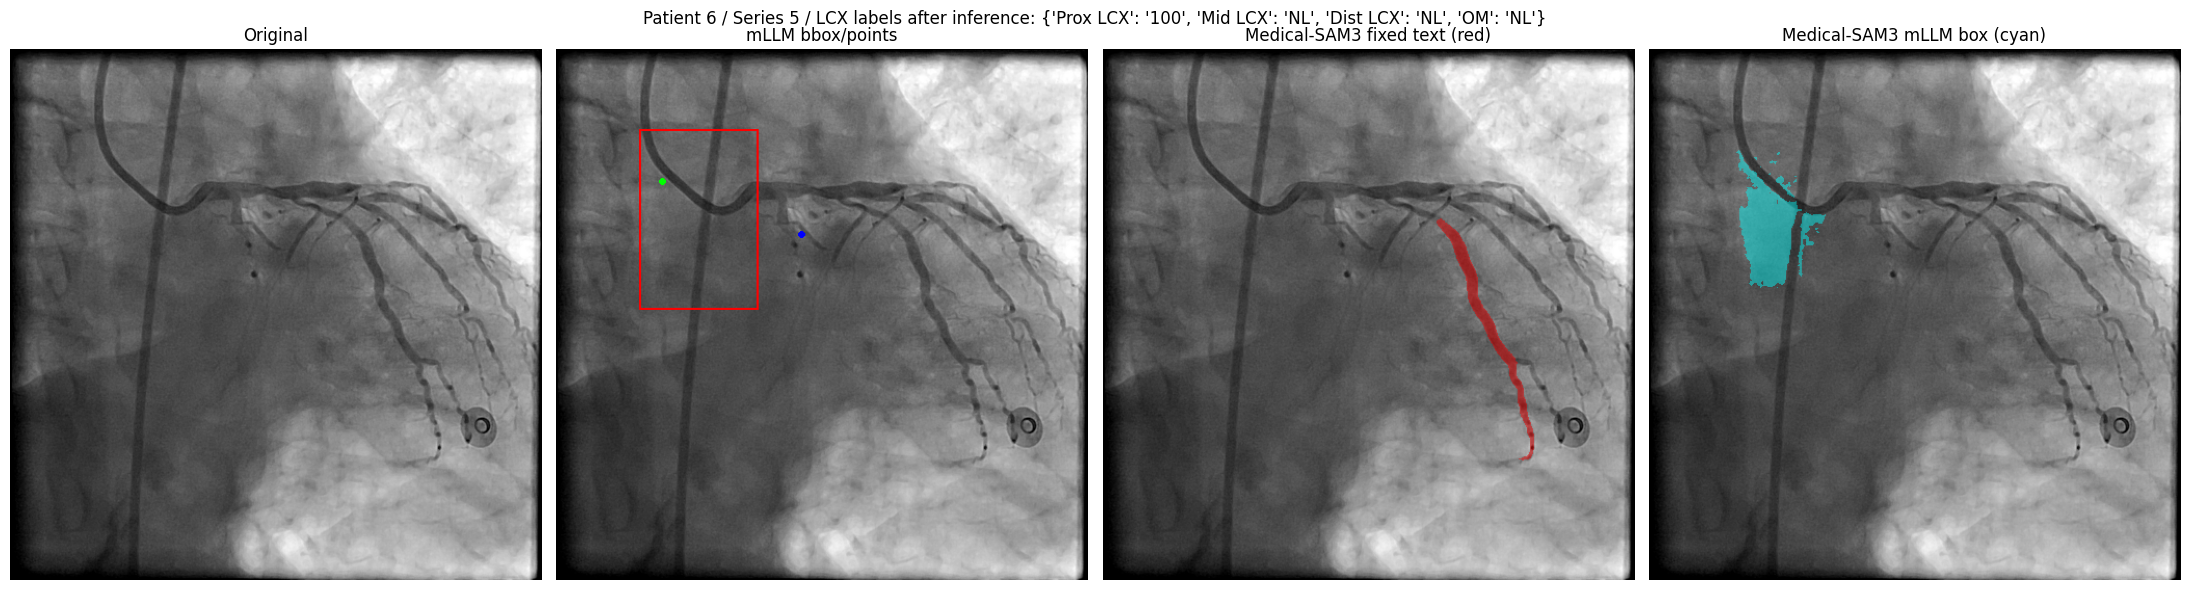

                                                     0
patient_id                                           6
series_id                                            5
selected_frame                          frame_0033.png
prox_lcx_label                                     100
mid_lcx_label                                       NL
dist_lcx_label                                      NL
om_label                                            NL
mllm_lcx_status                                visible
mllm_confidence                                    0.9
text_mask_nonempty                                True
mllm_box_mask_nonempty                            True
text_mask_area_ratio                          0.008522
mllm_box_mask_area_ratio                      0.018478
manual_lcx_main_trunk_found_0_or_1                    
manual_lad_or_om_false_positive_0_or_1                
manual_better_method_text_or_box                      
reviewer_note                                         
Overlay: /

In [ ]:
#@title 11. 결과 overlay, 엑셀 label 사후 비교, review CSV 저장

def overlay_mask(image, mask, color, alpha=0.45):
    output = image.astype(np.float32).copy()
    layer = np.zeros_like(output)
    layer[:] = color
    selected = mask.astype(bool)
    output[selected] = output[selected] * (1 - alpha) + layer[selected] * alpha
    return np.clip(output, 0, 255).astype(np.uint8)

prompt_preview_np = np.asarray(preview)
text_overlay = overlay_mask(rgb_image, text_mask_u8, (255, 0, 0))
box_overlay = overlay_mask(rgb_image, box_mask_u8, (0, 255, 255))

figure, axes = plt.subplots(1, 4, figsize=(22, 6))
panels = [
    (rgb_image, "Original"),
    (prompt_preview_np, "mLLM bbox/points"),
    (text_overlay, "Medical-SAM3 fixed text (red)"),
    (box_overlay, "Medical-SAM3 mLLM box (cyan)"),
]
for axis, (panel, title) in zip(axes, panels):
    axis.imshow(panel)
    axis.set_title(title)
    axis.axis("off")
figure.suptitle(
    f"Patient {PATIENT_ID} / Series {SERIES_ID} / "
    f"LCX labels after inference: {LCX_LABEL_AFTER_INFERENCE}",
    fontsize=12,
)
plt.tight_layout()
FINAL_OVERLAY_PATH = OUTPUT_DIR / "05_lcx_text_vs_mllm_box.png"
plt.savefig(FINAL_OVERLAY_PATH, dpi=160, bbox_inches="tight")
plt.show()

review_record = {
    "patient_id": PATIENT_ID,
    "series_id": SERIES_ID,
    "selected_frame": selected_image_path.name,
    "prox_lcx_label": LCX_LABEL_AFTER_INFERENCE["Prox LCX"],
    "mid_lcx_label": LCX_LABEL_AFTER_INFERENCE["Mid LCX"],
    "dist_lcx_label": LCX_LABEL_AFTER_INFERENCE["Dist LCX"],
    "om_label": LCX_LABEL_AFTER_INFERENCE["OM"],
    "mllm_lcx_status": grounding["lcx_status"],
    "mllm_confidence": grounding["confidence"],
    "text_mask_nonempty": bool(text_mask_u8.any()),
    "mllm_box_mask_nonempty": bool(box_mask_u8.any()),
    "text_mask_area_ratio": float(text_mask_u8.mean()),
    "mllm_box_mask_area_ratio": float(box_mask_u8.mean()),
    "manual_lcx_main_trunk_found_0_or_1": "",
    "manual_lad_or_om_false_positive_0_or_1": "",
    "manual_better_method_text_or_box": "",
    "reviewer_note": "",
}
review_df = pd.DataFrame([review_record])
REVIEW_CSV_PATH = OUTPUT_DIR / "06_lcx_manual_review.csv"
review_df.to_csv(REVIEW_CSV_PATH, index=False, encoding="utf-8-sig")

FINAL_JSON_PATH = OUTPUT_DIR / "07_lcx_experiment_result.json"
with open(FINAL_JSON_PATH, "w", encoding="utf-8") as file:
    json.dump(review_record, file, indent=2, ensure_ascii=False)

print(review_df.T)
print("Overlay:", FINAL_OVERLAY_PATH)
print("Review CSV:", REVIEW_CSV_PATH)
print("✅ LCX 1-class smoke experiment 완료 — 마지막 4개 manual 항목을 직접 채우세요.")


## 판정 및 다음 확장

이 실험의 성공 기준은 협착 등급 예측이 아니라 다음 세 가지다.

- mLLM이 left coronary frame에서 LCX main trunk를 올바르게 찾는다.
- LAD 또는 OM을 LCX로 오인하지 않는다.
- mLLM box를 받은 Medical-SAM3 mask가 고정 text prompt보다 안정적이다.

환자 6에서 연결을 확인한 뒤 환자 15, 25를 추가하고, RCA-only series를
negative control로 넣어 `not_visible` 동작을 확인한다. 이후에만 같은 JSON
schema를 LAD/RCA 등 나머지 구간으로 확장한다.


In [ ]:
#@title 10. 엑셀 label 기반 짧은 Medical-SAM3 text prompt 실험

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image


# ---------------------------------------------------------
# 1. 필요한 변수와 모델 확인
# ---------------------------------------------------------

assert "medsam3" in globals(), (
    "Medical-SAM3가 로드되지 않았습니다. "
    "먼저 Medical-SAM3 모델 로드 셀을 실행하세요."
)

assert "resize_mask" in globals(), (
    "resize_mask 함수가 없습니다. "
    "Medical-SAM3 import 셀을 확인하세요."
)

assert "LABELS_PATH" in globals(), (
    "LABELS_PATH가 정의되지 않았습니다."
)

assert "selected_frame_paths" in globals(), (
    "selected_frame_paths가 정의되지 않았습니다."
)

assert len(selected_frame_paths) == 1, (
    "이 실험에서는 프레임을 한 장만 사용합니다."
)


# ---------------------------------------------------------
# 2. 엑셀에서 환자와 목표 segment 확인
# ---------------------------------------------------------

PATIENT_ID = 6
TARGET_SEGMENT = "Prox LCX"

labels_df = pd.read_excel(
    LABELS_PATH
)

patient_rows = labels_df[
    labels_df["ID"] == PATIENT_ID
]

assert len(patient_rows) == 1, (
    f"엑셀에서 Patient {PATIENT_ID}를 "
    "정확히 하나 찾지 못했습니다."
)

patient_label = patient_rows.iloc[0]

left_coronary_series = str(
    patient_label["Left Coronary Series"]
)

target_grade_raw = patient_label[
    TARGET_SEGMENT
]

target_grade = str(
    target_grade_raw
).strip()

if target_grade.endswith(".0"):
    target_grade = target_grade[:-2]

print("Patient ID:", PATIENT_ID)
print(
    "Left Coronary Series:",
    left_coronary_series,
)
print(
    "Target segment:",
    TARGET_SEGMENT,
)
print(
    "Excel label:",
    target_grade,
)

assert target_grade != "NL", (
    f"{TARGET_SEGMENT}가 NL입니다. "
    "병변이 표시된 환자를 선택하세요."
)


# ---------------------------------------------------------
# 3. 짧은 text prompt 구성
# ---------------------------------------------------------

PROMPT_CONFIGS = [
    {
        "name": "anatomy",
        "prompt": (
            "proximal left circumflex "
            "coronary artery"
        ),
        "color": (255, 0, 0),
    },
    {
        "name": "stenosis",
        "prompt": (
            "proximal left circumflex "
            "coronary artery stenosis"
        ),
        "color": (0, 255, 255),
    },
]

# Excel label이 100인 경우 occlusion prompt도 비교
if target_grade == "100":
    PROMPT_CONFIGS.append(
        {
            "name": "occlusion",
            "prompt": (
                "proximal left circumflex "
                "coronary artery occlusion"
            ),
            "color": (255, 255, 0),
        }
    )

print("\n=== Medical-SAM3 short prompts ===")

for config in PROMPT_CONFIGS:
    print(
        f"- {config['name']}: "
        f"{config['prompt']}"
    )


# ---------------------------------------------------------
# 4. 선택 이미지 불러오기
# ---------------------------------------------------------

selected_image_path = (
    selected_frame_paths[0]
)

selected_image = Image.open(
    selected_image_path
).convert("RGB")

rgb_image = np.asarray(
    selected_image
)

image_height, image_width = (
    rgb_image.shape[:2]
)

print("\n선택 영상:", selected_image_path)
print(
    "이미지 크기:",
    image_width,
    "x",
    image_height,
)


# ---------------------------------------------------------
# 5. 결과 저장 폴더
# ---------------------------------------------------------

current_series_id = (
    selected_image_path.parent.name
)

DIRECT_OUTPUT_DIR = (
    PROJECT_DIR
    / "dca1_results"
    / "medicalsam3_label_prompt"
    / (
        f"patient_{PATIENT_ID:03d}_"
        f"series_{current_series_id}_"
        f"{selected_image_path.stem}"
    )
)

DIRECT_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "결과 저장 폴더:",
    DIRECT_OUTPUT_DIR,
)


# ---------------------------------------------------------
# 6. Mask 정규화 함수
# ---------------------------------------------------------

def normalize_medsam_mask(
    mask,
    output_height,
    output_width,
):
    if mask is None:
        return np.zeros(
            (
                output_height,
                output_width,
            ),
            dtype=np.uint8,
        )

    mask_array = np.asarray(
        mask
    ).squeeze()

    if mask_array.shape != (
        output_height,
        output_width,
    ):
        mask_array = resize_mask(
            mask_array,
            (
                output_height,
                output_width,
            ),
        )

    return (
        mask_array > 0
    ).astype(np.uint8)


def overlay_mask(
    image,
    mask,
    color,
    alpha=0.5,
):
    output = image.astype(
        np.float32
    ).copy()

    selected = mask.astype(bool)

    color_array = np.array(
        color,
        dtype=np.float32,
    )

    output[selected] = (
        output[selected] * (1 - alpha)
        + color_array * alpha
    )

    return np.clip(
        output,
        0,
        255,
    ).astype(np.uint8)


# ---------------------------------------------------------
# 7. 이미지를 한 번만 encoding
# ---------------------------------------------------------

encode_start = time.time()

image_state = medsam3.encode_image(
    rgb_image
)

encode_seconds = (
    time.time() - encode_start
)

print(
    "\nImage encoding seconds:",
    round(encode_seconds, 2),
)


# ---------------------------------------------------------
# 8. 짧은 prompt별 Medical-SAM3 추론
# ---------------------------------------------------------

mask_results = {}
result_records = []

for config in PROMPT_CONFIGS:
    prompt_name = config["name"]
    text_prompt = config["prompt"]

    inference_start = time.time()

    try:
        predicted_mask = (
            medsam3.predict_text(
                image_state,
                text_prompt,
            )
        )

        error_message = None

    except Exception as error:
        predicted_mask = None
        error_message = repr(error)

    inference_seconds = (
        time.time() - inference_start
    )

    normalized_mask = normalize_medsam_mask(
        predicted_mask,
        image_height,
        image_width,
    )

    mask_results[prompt_name] = (
        normalized_mask
    )

    mask_pixel_count = int(
        normalized_mask.sum()
    )

    mask_area_ratio = float(
        normalized_mask.mean()
    )

    result_records.append(
        {
            "prompt_name": prompt_name,
            "text_prompt": text_prompt,
            "mask_pixel_count": (
                mask_pixel_count
            ),
            "mask_area_ratio": (
                mask_area_ratio
            ),
            "inference_seconds": (
                inference_seconds
            ),
            "error": error_message,
        }
    )

    print()
    print("Prompt:", text_prompt)
    print(
        "Mask pixels:",
        mask_pixel_count,
    )
    print(
        "Area ratio:",
        round(mask_area_ratio, 6),
    )
    print(
        "Inference seconds:",
        round(inference_seconds, 2),
    )

    if error_message is not None:
        print(
            "오류:",
            error_message,
        )


# ---------------------------------------------------------
# 9. Prompt별 결과 시각화
# ---------------------------------------------------------

panel_count = (
    1 + len(PROMPT_CONFIGS)
)

figure, axes = plt.subplots(
    1,
    panel_count,
    figsize=(
        6 * panel_count,
        6,
    ),
)

axes[0].imshow(
    rgb_image
)

axes[0].set_title(
    "Original\n"
    f"Patient {PATIENT_ID} | "
    f"{TARGET_SEGMENT}={target_grade}"
)

axes[0].axis("off")

for panel_index, config in enumerate(
    PROMPT_CONFIGS,
    start=1,
):
    prompt_name = config["name"]
    text_prompt = config["prompt"]
    color = config["color"]

    mask = mask_results[
        prompt_name
    ]

    overlay = overlay_mask(
        rgb_image,
        mask,
        color,
        alpha=0.5,
    )

    axes[panel_index].imshow(
        overlay
    )

    axes[panel_index].set_title(
        f"{prompt_name}\n"
        f'"{text_prompt}"\n'
        f"pixels={int(mask.sum())}"
    )

    axes[panel_index].axis("off")

figure.suptitle(
    "Excel segment label → "
    "short Medical-SAM3 text prompt",
    fontsize=14,
)

plt.tight_layout()

DIRECT_OVERLAY_PATH = (
    DIRECT_OUTPUT_DIR
    / "label_guided_text_prompt_comparison.png"
)

plt.savefig(
    DIRECT_OVERLAY_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()


# ---------------------------------------------------------
# 10. Mask와 실험 정보 저장
# ---------------------------------------------------------

DIRECT_MASK_PATH = (
    DIRECT_OUTPUT_DIR
    / "label_guided_masks.npz"
)

np.savez_compressed(
    DIRECT_MASK_PATH,
    image_rgb_uint8=rgb_image,
    **{
        f"mask_{name}_uint8": mask
        for name, mask
        in mask_results.items()
    },
)

DIRECT_RESULT_PATH = (
    DIRECT_OUTPUT_DIR
    / "label_guided_result.json"
)

result_summary = {
    "patient_id": PATIENT_ID,
    "selected_frame": str(
        selected_image_path
    ),
    "left_coronary_series": (
        left_coronary_series
    ),
    "target_segment": (
        TARGET_SEGMENT
    ),
    "excel_grade": (
        target_grade
    ),
    "encode_seconds": (
        encode_seconds
    ),
    "prompt_results": (
        result_records
    ),
    "manual_review": {
        "anatomical_segment_found": None,
        "stenosis_region_found": None,
        "catheter_false_positive": None,
        "reviewer_note": "",
    },
}

with open(
    DIRECT_RESULT_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        result_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )

print()
print("✅ Label-guided Medical-SAM3 추론 완료")
print("Overlay:", DIRECT_OVERLAY_PATH)
print("Masks:", DIRECT_MASK_PATH)
print("Result:", DIRECT_RESULT_PATH)

In [ ]:
#@title 00. Google Drive 연결 및 전체 설정

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

import gc
import json
import os
import random
import re
import shutil
import subprocess
import sys
import time


# ---------------------------------------------------------
# 실험 설정
# ---------------------------------------------------------

PATIENT_ID = 6
SERIES_ID = 7
FRAME_NAME = "frame_0033.png"

TARGET_SEGMENT = "Prox LCX"


# ---------------------------------------------------------
# Google Drive 경로
# ---------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/"
    "[MacGyver]최종프로젝트/"
    "03_data/AngioCAD"
)

LABELS_PATH = (
    PROJECT_DIR
    / "AngioCAD_Labels.xlsx"
)

DRIVE_RAR_PARTS = [
    PROJECT_DIR
    / f"AngioCAD_Dataset.part{part}.rar"
    for part in range(1, 5)
]

MEDSAM3_WEIGHTS_DIR = (
    PROJECT_DIR
    / "external_data"
    / "MedicalSAM3"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "dca1_results"
    / "medicalsam3_label_prompt"
    / (
        f"patient_{PATIENT_ID:03d}_"
        f"series_{SERIES_ID}_"
        f"{Path(FRAME_NAME).stem}"
    )
)


# ---------------------------------------------------------
# Colab 로컬 경로
# ---------------------------------------------------------

MEDSAM3_REPO_DIR = Path(
    "/content/Medical-SAM3"
)

LOCAL_RAR_DIR = Path(
    "/content/AngioCAD_RAR_parts"
)

LOCAL_EXTRACT_ROOT = Path(
    "/content/AngioCAD_label_prompt_case"
)


# ---------------------------------------------------------
# 폴더 생성
# ---------------------------------------------------------

MEDSAM3_WEIGHTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

LOCAL_RAR_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

LOCAL_EXTRACT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


# ---------------------------------------------------------
# GPU 확인
# ---------------------------------------------------------

gpu_info = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=name,memory.total",
        "--format=csv,noheader",
    ],
    capture_output=True,
    text=True,
)

assert gpu_info.returncode == 0, (
    "Colab 런타임을 GPU로 설정하세요."
)

print("GPU:", gpu_info.stdout.strip())
print("Patient:", PATIENT_ID)
print("Series:", SERIES_ID)
print("Frame:", FRAME_NAME)
print("Target segment:", TARGET_SEGMENT)
print("Project:", PROJECT_DIR)
print("Output:", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA L4, 23034 MiB
Patient: 6
Series: 7
Frame: frame_0033.png
Target segment: Prox LCX
Project: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD
Output: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/dca1_results/medicalsam3_label_prompt/patient_006_series_7_frame_0033


In [ ]:
#@title 01. Medical-SAM3 패키지 설치

MEDSAM3_REPO_URL = (
    "https://github.com/"
    "AIM-Research-Lab/"
    "Medical-SAM3.git"
)


# ---------------------------------------------------------
# 공식 저장소 clone
# ---------------------------------------------------------

if MEDSAM3_REPO_DIR.exists():
    print(
        "기존 Medical-SAM3 저장소 재사용:",
        MEDSAM3_REPO_DIR,
    )

else:
    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            MEDSAM3_REPO_URL,
            str(MEDSAM3_REPO_DIR),
        ],
        check=True,
    )


# ---------------------------------------------------------
# pip 설치 함수
# ---------------------------------------------------------

def pip_install(*packages):
    command = [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--no-cache-dir",
        *packages,
    ]

    print(
        "설치:",
        " ".join(packages),
    )

    subprocess.run(
        command,
        check=True,
    )


# ---------------------------------------------------------
# Python 3.13 호환 NumPy/SciPy
# ---------------------------------------------------------

pip_install(
    "numpy>=2.1,<2.3",
    "scipy>=1.15,<1.16",
)


# ---------------------------------------------------------
# Medical-SAM3를 dependency 자동 설치 없이 등록
# ---------------------------------------------------------

pip_install(
    "--no-deps",
    "-e",
    str(MEDSAM3_REPO_DIR),
)


# ---------------------------------------------------------
# Medical-SAM3 inference 필수 패키지
# ---------------------------------------------------------

pip_install(
    "timm>=1.0.17",
    "tqdm",
    "ftfy==6.1.1",
    "regex",
    "iopath>=0.1.10",
    "typing_extensions",
    "huggingface_hub",
    "opencv-python-headless",
    "scikit-image",
    "matplotlib",
    "pandas",
    "pillow",
    "openpyxl",
    "fvcore",
    "fairscale",
    "einops",
    "torchmetrics",
    "hydra-core",
)


# ---------------------------------------------------------
# 설치 환경 별도 프로세스에서 검사
# ---------------------------------------------------------

environment_check = subprocess.run(
    [
        sys.executable,
        "-c",
        (
            "import numpy, scipy, torch; "
            "print('numpy', numpy.__version__); "
            "print('scipy', scipy.__version__); "
            "print('torch', torch.__version__)"
        ),
    ],
    capture_output=True,
    text=True,
)

print(environment_check.stdout)

if environment_check.returncode != 0:
    print(environment_check.stderr)

assert environment_check.returncode == 0, (
    "NumPy/SciPy import 검사에 실패했습니다. "
    "런타임을 재시작한 뒤 00번부터 다시 실행하세요."
)


# ---------------------------------------------------------
# commit 기록
# ---------------------------------------------------------

commit_sha = subprocess.run(
    [
        "git",
        "-C",
        str(MEDSAM3_REPO_DIR),
        "rev-parse",
        "HEAD",
    ],
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

print("Medical-SAM3 commit:", commit_sha)
print("✅ Medical-SAM3 패키지 설치 완료")

기존 Medical-SAM3 저장소 재사용: /content/Medical-SAM3
설치: numpy>=2.1,<2.3 scipy>=1.15,<1.16
설치: --no-deps -e /content/Medical-SAM3
설치: timm>=1.0.17 tqdm ftfy==6.1.1 regex iopath>=0.1.10 typing_extensions huggingface_hub opencv-python-headless scikit-image matplotlib pandas pillow openpyxl fvcore fairscale einops torchmetrics hydra-core
numpy 2.1.3
scipy 1.15.3
torch 2.11.0+cu128

Medical-SAM3 commit: 4164d261b5a8c9fc1015a2e21537280a19c972c5
✅ Medical-SAM3 패키지 설치 완료


In [ ]:
#@title 02. 라이브러리 import 및 Excel label 확인

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import torch

from PIL import Image


# ---------------------------------------------------------
# 버전 확인
# ---------------------------------------------------------

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("PyTorch:", torch.__version__)
print(
    "GPU:",
    torch.cuda.get_device_name(0),
)


# ---------------------------------------------------------
# Seed 고정
# ---------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


# ---------------------------------------------------------
# Excel 파일 확인
# ---------------------------------------------------------

assert LABELS_PATH.exists(), (
    f"AngioCAD_Labels.xlsx가 없습니다: "
    f"{LABELS_PATH}"
)

labels_df = pd.read_excel(
    LABELS_PATH,
    sheet_name="Labels",
)

required_columns = [
    "ID",
    "Right Coronary Series",
    "Left Coronary Series",
    "Prox LCX",
    "Mid LCX",
    "Dist LCX",
    "OM",
]

for column_name in required_columns:
    assert column_name in labels_df.columns, (
        f"엑셀에 {column_name} 열이 없습니다."
    )


# ---------------------------------------------------------
# 환자 행 선택
# ---------------------------------------------------------

patient_rows = labels_df.loc[
    labels_df["ID"].astype(int)
    == PATIENT_ID
]

assert len(patient_rows) == 1, (
    f"Patient {PATIENT_ID}의 label을 "
    "정확히 하나 찾지 못했습니다."
)

label_row = patient_rows.iloc[0]


# ---------------------------------------------------------
# Series 표기 파싱
# 예: "5-8" → [5, 6, 7, 8]
# ---------------------------------------------------------

def expand_series_spec(value):
    result = set()

    text = str(value).replace(
        " ",
        "",
    )

    for token in text.split(","):
        if (
            not token
            or token.lower() == "nan"
        ):
            continue

        if "-" in token:
            start, end = (
                int(part)
                for part in token.split(
                    "-",
                    1,
                )
            )

            result.update(
                range(
                    start,
                    end + 1,
                )
            )

        else:
            result.add(
                int(float(token))
            )

    return sorted(result)


left_series = expand_series_spec(
    label_row[
        "Left Coronary Series"
    ]
)

assert SERIES_ID in left_series, (
    f"Series {SERIES_ID}가 Patient {PATIENT_ID}의 "
    f"Left Coronary Series {left_series}에 없습니다."
)


# ---------------------------------------------------------
# LCX label 확인
# ---------------------------------------------------------

def clean_excel_label(value):
    text = str(value).strip()

    if text.endswith(".0"):
        text = text[:-2]

    return text


LCX_LABELS = {
    "Prox LCX": clean_excel_label(
        label_row["Prox LCX"]
    ),
    "Mid LCX": clean_excel_label(
        label_row["Mid LCX"]
    ),
    "Dist LCX": clean_excel_label(
        label_row["Dist LCX"]
    ),
    "OM": clean_excel_label(
        label_row["OM"]
    ),
}

assert TARGET_SEGMENT in LCX_LABELS, (
    f"지원하지 않는 target입니다: "
    f"{TARGET_SEGMENT}"
)

TARGET_GRADE = LCX_LABELS[
    TARGET_SEGMENT
]

print()
print("Patient:", PATIENT_ID)
print("Left coronary series:", left_series)
print("Selected series:", SERIES_ID)
print("LCX labels:", LCX_LABELS)
print("Target segment:", TARGET_SEGMENT)
print("Target grade:", TARGET_GRADE)

assert TARGET_GRADE != "NL", (
    f"{TARGET_SEGMENT} label이 NL입니다."
)

print("✅ Excel label 확인 완료")

NumPy: 2.1.3
SciPy: 1.15.3
PyTorch: 2.11.0+cu128
GPU: NVIDIA L4

Patient: 6
Left coronary series: [5, 6, 7, 8]
Selected series: 7
LCX labels: {'Prox LCX': '100', 'Mid LCX': 'NL', 'Dist LCX': 'NL', 'OM': 'NL'}
Target segment: Prox LCX
Target grade: 100
✅ Excel label 확인 완료


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


In [ ]:
#@title 03. RAR 로컬 복사 및 선택 Series 추출

# ---------------------------------------------------------
# RAR part 존재 확인
# ---------------------------------------------------------

for drive_part in DRIVE_RAR_PARTS:
    assert drive_part.exists(), (
        f"RAR 파일이 없습니다: {drive_part}"
    )

print("✅ Drive에서 RAR part 4개 확인")


# ---------------------------------------------------------
# unrar 및 rsync 설치
# ---------------------------------------------------------

if (
    shutil.which("unrar") is None
    or shutil.which("rsync") is None
):
    subprocess.run(
        [
            "apt-get",
            "update",
            "-qq",
        ],
        check=True,
    )

    subprocess.run(
        [
            "apt-get",
            "install",
            "-y",
            "-qq",
            "unrar",
            "rsync",
        ],
        check=True,
    )

print("unrar:", shutil.which("unrar"))
print("rsync:", shutil.which("rsync"))


# ---------------------------------------------------------
# Drive RAR → Colab 로컬 복사
# ---------------------------------------------------------

LOCAL_RAR_PARTS = []

for drive_part in DRIVE_RAR_PARTS:
    local_part = (
        LOCAL_RAR_DIR
        / drive_part.name
    )

    print()
    print(
        "복사 확인:",
        drive_part.name,
    )

    copy_result = subprocess.run(
        [
            "rsync",
            "-ah",
            "--partial",
            "--inplace",
            "--info=progress2",
            str(drive_part),
            str(local_part),
        ]
    )

    assert copy_result.returncode == 0, (
        f"{drive_part.name} 로컬 복사 실패입니다. "
        "Transport endpoint 오류라면 Drive를 "
        "다시 연결한 후 이 셀을 재실행하세요."
    )

    assert local_part.exists(), (
        f"로컬 파일이 생성되지 않았습니다: "
        f"{local_part}"
    )

    drive_size = drive_part.stat().st_size
    local_size = local_part.stat().st_size

    assert drive_size == local_size, (
        f"{drive_part.name} 크기가 다릅니다. "
        f"Drive={drive_size}, Local={local_size}"
    )

    LOCAL_RAR_PARTS.append(
        local_part
    )

    print(
        "완료:",
        local_part,
        f"({local_size / 1024**3:.2f} GB)",
    )

print()
print("✅ RAR part 4개 로컬 복사 완료")


# ---------------------------------------------------------
# 선택 Series 추출
# ---------------------------------------------------------

LOCAL_RAR_FIRST_PART = (
    LOCAL_RAR_PARTS[0]
)

SERIES_DIR = (
    LOCAL_EXTRACT_ROOT
    / "AngioCAD_Dataset"
    / str(PATIENT_ID)
    / str(SERIES_ID)
)

allowed_suffixes = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff",
}


def natural_key(path):
    return [
        int(part)
        if part.isdigit()
        else part.lower()
        for part in re.split(
            r"(\d+)",
            path.name,
        )
    ]


def find_extracted_frames():
    if not SERIES_DIR.exists():
        return []

    return sorted(
        [
            path
            for path in SERIES_DIR.rglob("*")
            if path.suffix.lower()
            in allowed_suffixes
        ],
        key=natural_key,
    )


all_frame_paths = (
    find_extracted_frames()
)

if all_frame_paths:
    print(
        "기존 추출 결과 재사용:",
        SERIES_DIR,
    )

else:
    series_pattern = (
        f"AngioCAD_Dataset/"
        f"{PATIENT_ID}/"
        f"{SERIES_ID}/*"
    )

    print(
        "RAR 추출 pattern:",
        series_pattern,
    )

    extraction = subprocess.run(
        [
            "unrar",
            "x",
            "-o+",
            "-idq",
            str(LOCAL_RAR_FIRST_PART),
            series_pattern,
            str(LOCAL_EXTRACT_ROOT) + "/",
        ],
        capture_output=True,
        text=True,
    )

    if extraction.returncode != 0:
        print(
            extraction.stdout[-3000:]
        )
        print(
            extraction.stderr[-3000:]
        )

    assert extraction.returncode == 0, (
        "선택 Series 압축 해제 실패"
    )

    all_frame_paths = (
        find_extracted_frames()
    )


assert all_frame_paths, (
    f"영상 프레임을 찾지 못했습니다: "
    f"{SERIES_DIR}"
)

print()
print("Series 폴더:", SERIES_DIR)
print("추출 프레임 수:", len(all_frame_paths))
print("첫 프레임:", all_frame_paths[0])
print("마지막 프레임:", all_frame_paths[-1])
print("✅ 선택 Series 추출 완료")

✅ Drive에서 RAR part 4개 확인
unrar: /usr/bin/unrar
rsync: /usr/bin/rsync

복사 확인: AngioCAD_Dataset.part1.rar
완료: /content/AngioCAD_RAR_parts/AngioCAD_Dataset.part1.rar (3.91 GB)

복사 확인: AngioCAD_Dataset.part2.rar
완료: /content/AngioCAD_RAR_parts/AngioCAD_Dataset.part2.rar (3.91 GB)

복사 확인: AngioCAD_Dataset.part3.rar
완료: /content/AngioCAD_RAR_parts/AngioCAD_Dataset.part3.rar (3.91 GB)

복사 확인: AngioCAD_Dataset.part4.rar
완료: /content/AngioCAD_RAR_parts/AngioCAD_Dataset.part4.rar (3.56 GB)

✅ RAR part 4개 로컬 복사 완료
RAR 추출 pattern: AngioCAD_Dataset/6/7/*

Series 폴더: /content/AngioCAD_label_prompt_case/AngioCAD_Dataset/6/7
추출 프레임 수: 57
첫 프레임: /content/AngioCAD_label_prompt_case/AngioCAD_Dataset/6/7/frame_0000.png
마지막 프레임: /content/AngioCAD_label_prompt_case/AngioCAD_Dataset/6/7/frame_0056.png
✅ 선택 Series 추출 완료


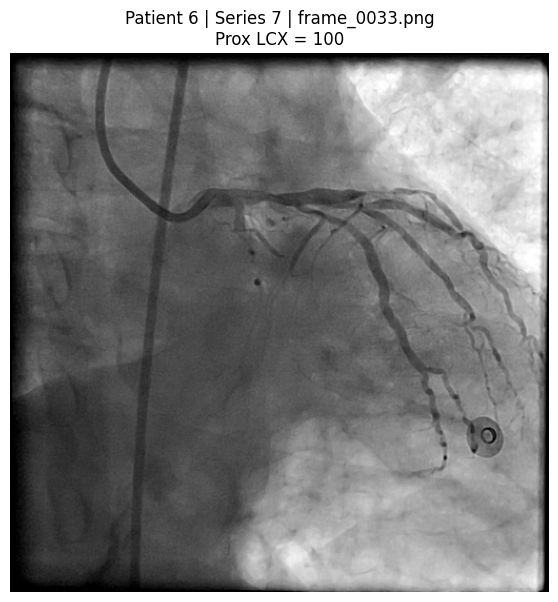

선택 영상: /content/AngioCAD_label_prompt_case/AngioCAD_Dataset/6/7/frame_0033.png
이미지 크기: 512 x 512
선택 영상 저장: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/dca1_results/medicalsam3_label_prompt/patient_006_series_7_frame_0033/01_selected_frame.png
✅ 프레임 선택 완료


In [ ]:
#@title 04. Medical-SAM3에 사용할 프레임 선택

frame_candidates = [
    path
    for path in all_frame_paths
    if path.name == FRAME_NAME
]

assert len(frame_candidates) == 1, (
    f"Series {SERIES_ID}에서 "
    f"{FRAME_NAME}을 정확히 하나 찾지 못했습니다. "
    f"검색 결과: {frame_candidates}"
)

selected_frame_paths = [
    frame_candidates[0]
]

selected_image_path = (
    selected_frame_paths[0]
)

selected_image = Image.open(
    selected_image_path
).convert("RGB")

rgb_image = np.asarray(
    selected_image
)

image_height, image_width = (
    rgb_image.shape[:2]
)

plt.figure(figsize=(7, 7))
plt.imshow(rgb_image)
plt.title(
    f"Patient {PATIENT_ID} | "
    f"Series {SERIES_ID} | "
    f"{FRAME_NAME}\n"
    f"{TARGET_SEGMENT} = {TARGET_GRADE}"
)
plt.axis("off")
plt.show()

SELECTED_FRAME_OUTPUT_PATH = (
    OUTPUT_DIR
    / "01_selected_frame.png"
)

selected_image.save(
    SELECTED_FRAME_OUTPUT_PATH
)

print("선택 영상:", selected_image_path)
print(
    "이미지 크기:",
    image_width,
    "x",
    image_height,
)
print(
    "선택 영상 저장:",
    SELECTED_FRAME_OUTPUT_PATH,
)
print("✅ 프레임 선택 완료")

In [ ]:
#@title 05. Medical-SAM3 checkpoint 준비 및 모델 로드

import gc

from huggingface_hub import (
    hf_hub_download,
)


# ---------------------------------------------------------
# 혹시 GPU에 남아 있는 mLLM 메모리 제거
# ---------------------------------------------------------

variables_to_clear = [
    "mllm",
    "mllm_processor",
    "model_inputs",
    "generated_ids",
    "image_inputs",
    "video_inputs",
]

for variable_name in variables_to_clear:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()
torch.cuda.empty_cache()


# ---------------------------------------------------------
# Medical-SAM3 inference 모듈 import
# ---------------------------------------------------------

SAM3_INFERENCE_DIR = (
    MEDSAM3_REPO_DIR
    / "inference"
)

for import_path in (
    MEDSAM3_REPO_DIR,
    SAM3_INFERENCE_DIR,
):
    import_path_text = str(
        import_path
    )

    if import_path_text not in sys.path:
        sys.path.insert(
            0,
            import_path_text,
        )

import sam3_inference

from sam3_inference import (
    SAM3Model,
    resize_mask,
)


# 공식 wrapper의 SAM3_ROOT 누락 보완
sam3_inference.SAM3_ROOT = (
    sam3_inference._REPO_ROOT
)

print(
    "SAM3_ROOT:",
    sam3_inference.SAM3_ROOT,
)


# ---------------------------------------------------------
# Checkpoint 준비
# ---------------------------------------------------------

MEDSAM3_CHECKPOINT_PATH = (
    MEDSAM3_WEIGHTS_DIR
    / "checkpoint_2D.pt"
)

if MEDSAM3_CHECKPOINT_PATH.exists():
    print(
        "기존 checkpoint 재사용:",
        MEDSAM3_CHECKPOINT_PATH,
    )

else:
    print(
        "Medical-SAM3 checkpoint 다운로드 시작"
    )

    hf_hub_download(
        repo_id="ChongCong/Medical-SAM3",
        filename="checkpoint_2D.pt",
        local_dir=str(
            MEDSAM3_WEIGHTS_DIR
        ),
    )

assert MEDSAM3_CHECKPOINT_PATH.exists(), (
    "Medical-SAM3 checkpoint를 "
    "찾을 수 없습니다."
)


# ---------------------------------------------------------
# 모델 로드
# ---------------------------------------------------------

torch.cuda.empty_cache()

MEDSAM3_CONFIDENCE_THRESHOLD = 0.1

medsam3 = SAM3Model(
    confidence_threshold=(
        MEDSAM3_CONFIDENCE_THRESHOLD
    ),
    device="cuda",
    checkpoint_path=str(
        MEDSAM3_CHECKPOINT_PATH
    ),
)

load_start = time.time()

medsam3.load_model()

load_seconds = (
    time.time() - load_start
)

allocated_gb = (
    torch.cuda.memory_allocated()
    / 1024**3
)

print(
    "Medical-SAM3 load seconds:",
    round(load_seconds, 2),
)

print(
    "GPU allocated:",
    round(allocated_gb, 2),
    "GB",
)

print("✅ Medical-SAM3 모델 로드 완료")

SAM3_ROOT: /content/Medical-SAM3
기존 checkpoint 재사용: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/external_data/MedicalSAM3/checkpoint_2D.pt
Loading SAM3 model from checkpoint: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/external_data/MedicalSAM3/checkpoint_2D.pt
Loading custom checkpoint: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/external_data/MedicalSAM3/checkpoint_2D.pt
SAM3 model loaded successfully!
Medical-SAM3 load seconds: 906.72
GPU allocated: 3.14 GB
✅ Medical-SAM3 모델 로드 완료


=== Excel label ===
Prox LCX = 100

=== Short prompts ===
excel_exact → Prox LCX
short_expanded → proximal LCX
full_vessel_name → left circumflex coronary artery

Candidate threshold: 0.01
Top-K: 5

Original threshold: 0.1
Temporary threshold: 0.01

Image encoding seconds: 0.04

Prompt: Prox LCX
전체 후보 수: 200
Inference seconds: 0.23
  rank=1 | score=0.5586 | pixels=7394 | box=[84.0999984741211, 14.0, 496.29998779296875, 399.29998779296875]
  rank=2 | score=0.3633 | pixels=2998 | box=[81.19999694824219, 96.5, 489.1000061035156, 394.5]
  rank=3 | score=0.3438 | pixels=2557 | box=[312.0, 161.5, 459.79998779296875, 396.6000061035156]
  rank=4 | score=0.3398 | pixels=1724 | box=[323.29998779296875, 143.8000030517578, 494.5, 333.6000061035156]
  rank=5 | score=0.3320 | pixels=3161 | box=[82.30000305175781, 79.4000015258789, 489.5, 392.5]

Prompt: proximal LCX
전체 후보 수: 200
Inference seconds: 0.08
  rank=1 | score=0.5586 | pixels=5722 | box=[83.5, 18.700000762939453, 489.79998779296875, 394.200

/tmp/ipykernel_2935/3340369825.py:611: UserWarning: Glyph 44033 (\N{HANGUL SYLLABLE GAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2935/3340369825.py:611: UserWarning: Glyph 54665 (\N{HANGUL SYLLABLE HAENG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2935/3340369825.py:611: UserWarning: Glyph 50640 (\N{HANGUL SYLLABLE E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2935/3340369825.py:611: UserWarning: Glyph 49436 (\N{HANGUL SYLLABLE SEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2935/3340369825.py:611: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2935/3340369825.py:611: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2935/3340369825.py:611: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tig

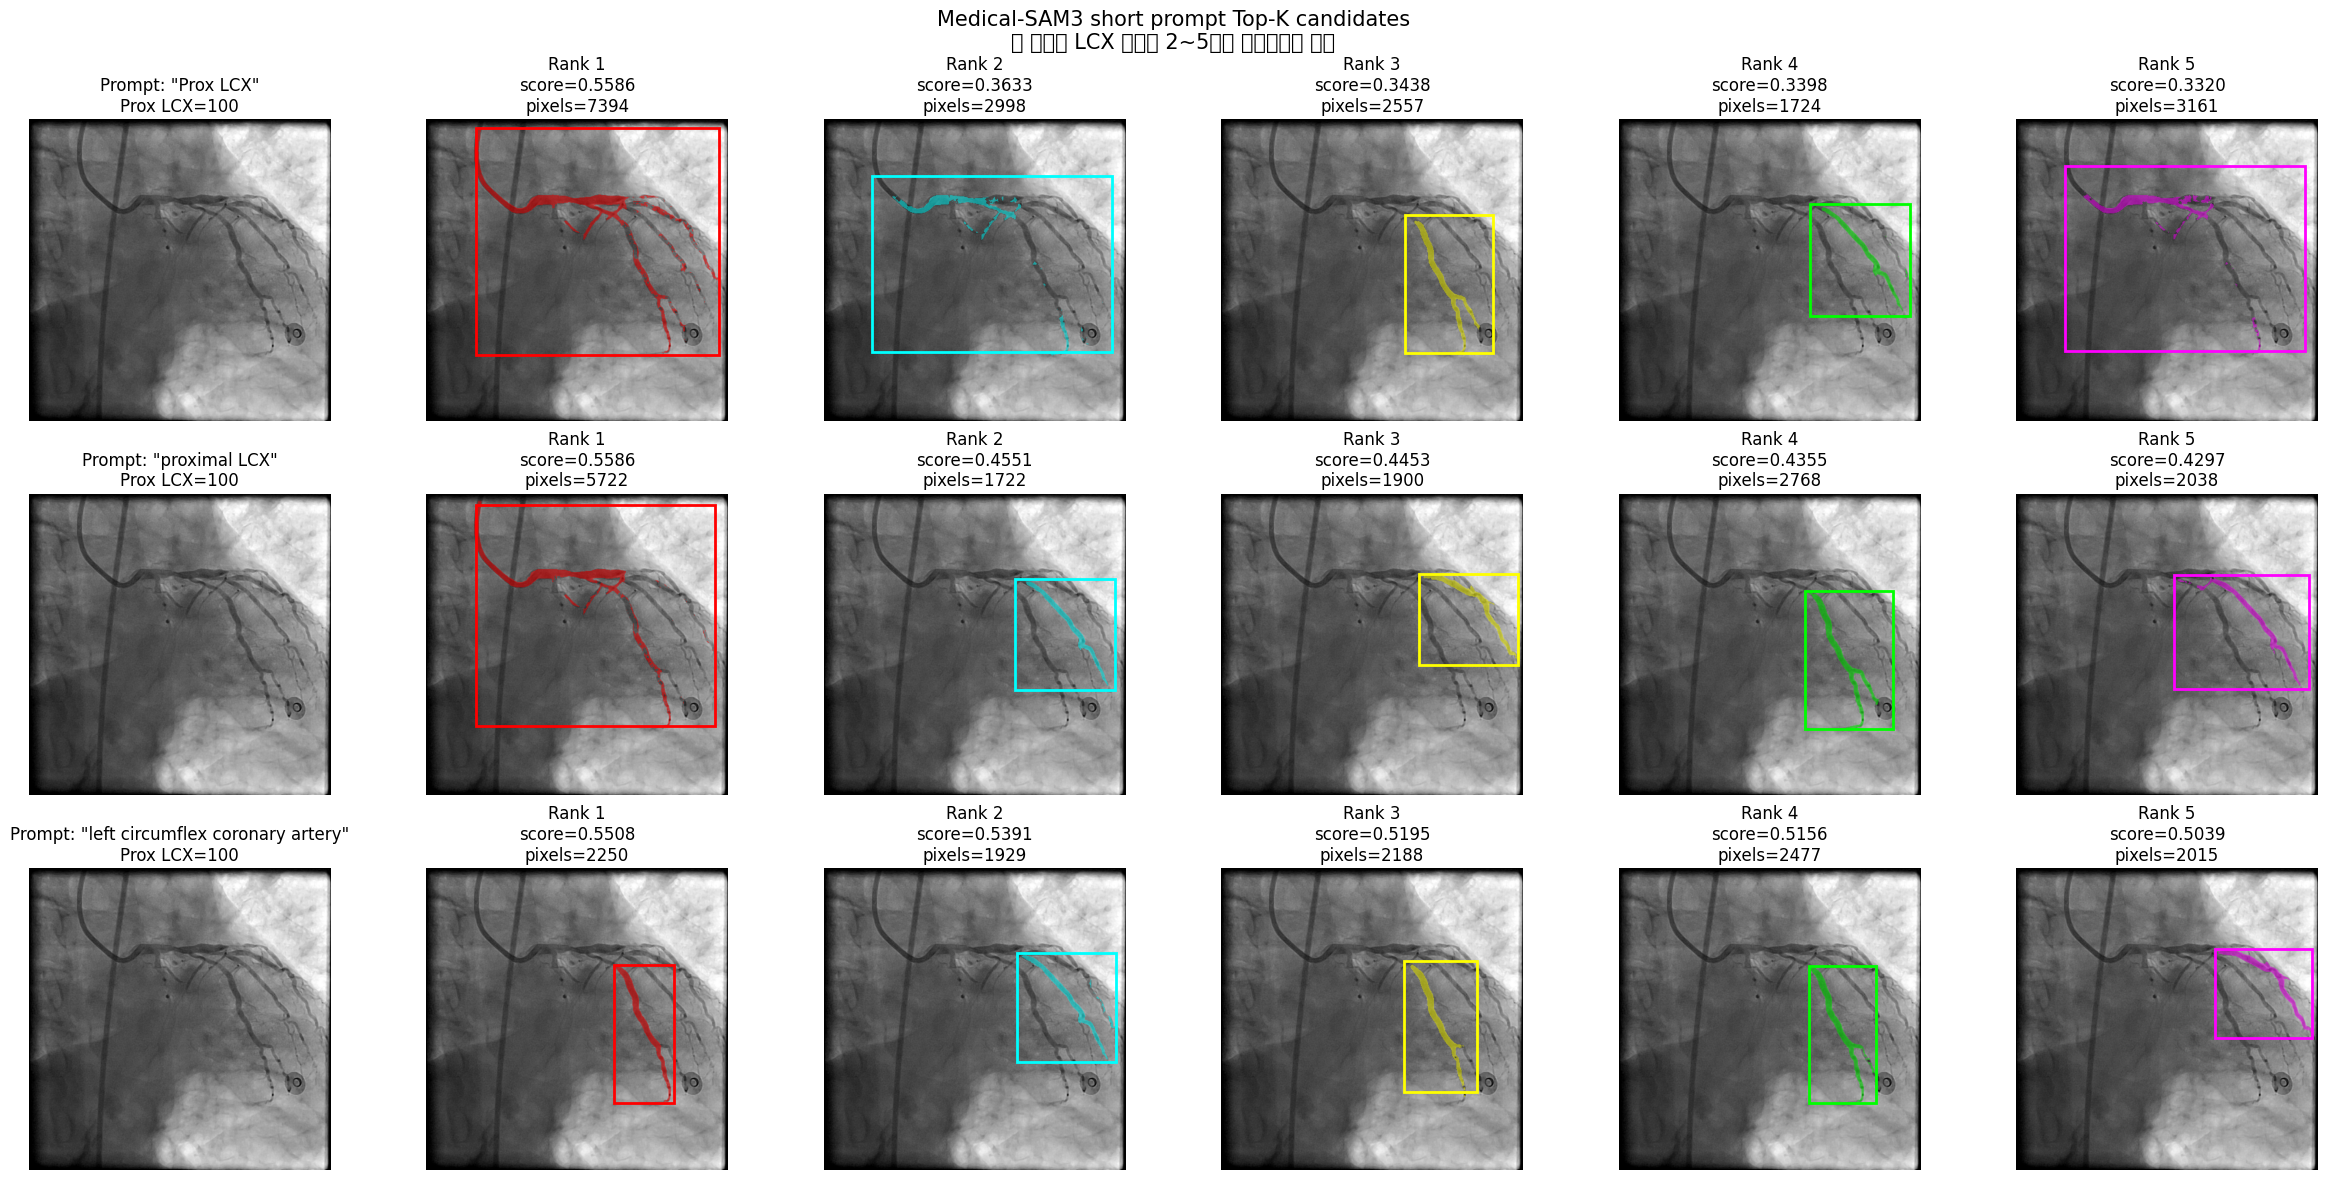


=== Top-1 mask Dice comparison ===
excel_exact vs short_expanded: Dice=0.8565
excel_exact vs full_vessel_name: Dice=0.2655
short_expanded vs full_vessel_name: Dice=0.2782
=== Patient information ===
Patient: 6
Series: 7
Frame: frame_0033.png

=== Vessel prompts and Excel labels ===
LM: "left main artery" | LM=NL
LAD: "left anterior descending artery" | Prox=76-90, Mid=100, Dist=NL
LCX: "left circumflex artery" | Prox=100, Mid=NL, Dist=NL
OM: "obtuse marginal artery" | OM=NL

Image encoding seconds: 0.037

Vessel: LM
Prompt: left main artery
Excel label: LM=NL
Mask pixels: 2268
Area ratio: 0.008652
Inference seconds: 0.228

Vessel: LAD
Prompt: left anterior descending artery
Excel label: Prox=76-90, Mid=100, Dist=NL
Mask pixels: 2016
Area ratio: 0.00769
Inference seconds: 0.088

Vessel: LCX
Prompt: left circumflex artery
Excel label: Prox=100, Mid=NL, Dist=NL
Mask pixels: 2274
Area ratio: 0.008675
Inference seconds: 0.088

Vessel: OM
Prompt: obtuse marginal artery
Excel label: OM=NL
Ma

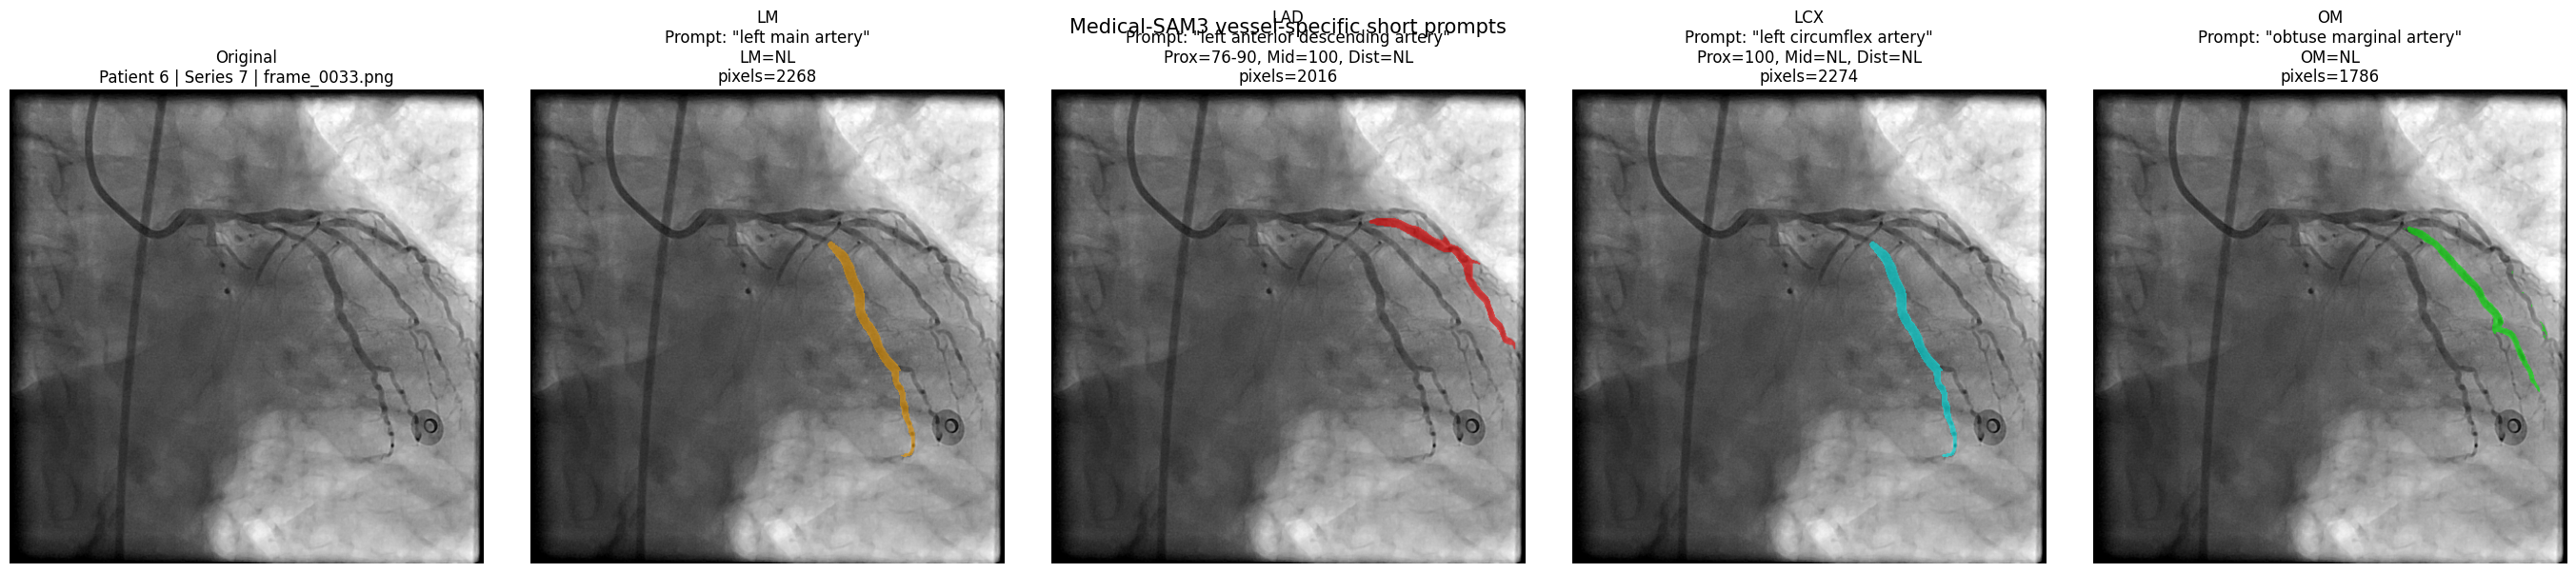

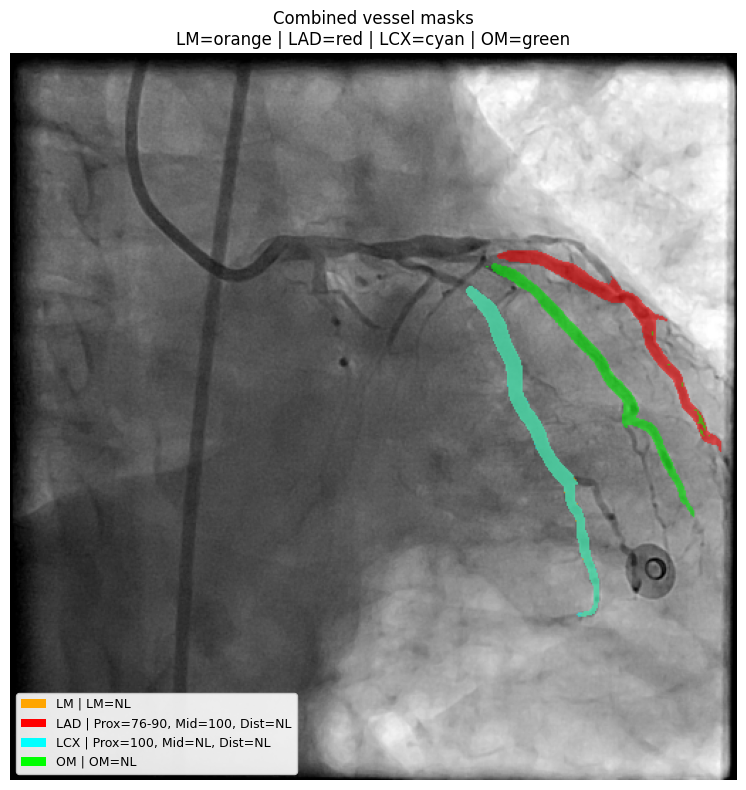


=== Pairwise mask Dice ===
LM : ['1.000', '0.000', '0.996', '0.000']
LAD : ['0.000', '1.000', '0.000', '0.025']
LCX : ['0.996', '0.000', '1.000', '0.000']
OM : ['0.000', '0.025', '0.000', '1.000']


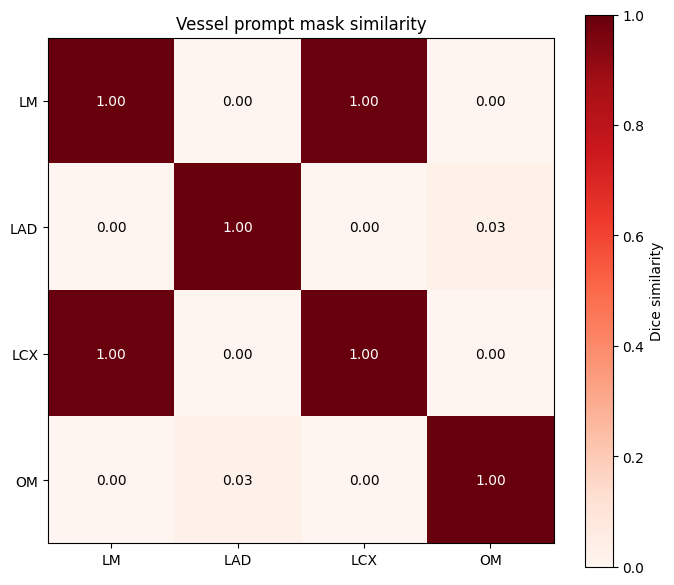


Maximum cross-vessel Dice: 0.996
Mean cross-vessel Dice: 0.1702
⚠️ 서로 다른 혈관 prompt가 거의 동일한 mask를 반환했습니다.
Medical-SAM3가 혈관 이름을 충분히 구분하지 못했을 가능성이 큽니다.

✅ 주요 좌관상동맥 혈관 비교 완료
Individual comparison: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/dca1_results/medicalsam3_label_prompt/patient_006_series_7_frame_0033/08_major_vessel_prompt_comparison.png
Combined overlay: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/dca1_results/medicalsam3_label_prompt/patient_006_series_7_frame_0033/09_combined_major_vessel_masks.png
Dice heatmap: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/dca1_results/medicalsam3_label_prompt/patient_006_series_7_frame_0033/10_major_vessel_dice_heatmap.png
Masks: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/dca1_results/medicalsam3_label_prompt/patient_006_series_7_frame_0033/11_major_vessel_masks.npz
Result: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/dca1_results/medicalsam3_label_prompt/patient_006_series_7_fra

In [ ]:
#@title 06. Prox LCX 짧은 prompt의 Medical-SAM3 Top-K 후보 확인

import json
import time
import numpy as np
import matplotlib.pyplot as plt
import torch

from matplotlib.patches import Rectangle


# ---------------------------------------------------------
# 1. 실행 조건 확인
# ---------------------------------------------------------

assert "medsam3" in globals(), (
    "먼저 05번 Medical-SAM3 로드 셀을 실행하세요."
)

assert "rgb_image" in globals(), (
    "먼저 04번 프레임 선택 셀을 실행하세요."
)

assert "TARGET_SEGMENT" in globals()
assert "TARGET_GRADE" in globals()
assert "OUTPUT_DIR" in globals()
assert "resize_mask" in globals()


# ---------------------------------------------------------
# 2. 짧은 prompt만 사용
# ---------------------------------------------------------

PROMPT_CONFIGS = [
    {
        "name": "excel_exact",
        "prompt": TARGET_SEGMENT,
    },
    {
        "name": "short_expanded",
        "prompt": "proximal LCX",
    },
    {
        "name": "full_vessel_name",
        "prompt": (
            "left circumflex coronary artery"
        ),
    },
]

TOP_K = 5

# 기존 0.1보다 낮춰서 낮은 점수 후보도 확인
CANDIDATE_THRESHOLD = 0.01

print("=== Excel label ===")
print(
    TARGET_SEGMENT,
    "=",
    TARGET_GRADE,
)

print()
print("=== Short prompts ===")

for config in PROMPT_CONFIGS:
    print(
        config["name"],
        "→",
        config["prompt"],
    )

print()
print(
    "Candidate threshold:",
    CANDIDATE_THRESHOLD,
)

print(
    "Top-K:",
    TOP_K,
)


# ---------------------------------------------------------
# 3. Mask 변환 함수
# ---------------------------------------------------------

def normalize_candidate_mask(mask):
    mask_array = np.asarray(
        mask
    ).squeeze()

    if mask_array.shape != (
        image_height,
        image_width,
    ):
        mask_array = resize_mask(
            mask_array,
            (
                image_height,
                image_width,
            ),
        )

    return (
        mask_array > 0
    ).astype(np.uint8)


def overlay_mask(
    image,
    mask,
    color=(255, 0, 0),
    alpha=0.5,
):
    output = image.astype(
        np.float32
    ).copy()

    selected = mask.astype(bool)

    color_array = np.array(
        color,
        dtype=np.float32,
    )

    output[selected] = (
        output[selected] * (1 - alpha)
        + color_array * alpha
    )

    return np.clip(
        output,
        0,
        255,
    ).astype(np.uint8)


def binary_dice(mask_a, mask_b):
    mask_a = mask_a.astype(bool)
    mask_b = mask_b.astype(bool)

    denominator = (
        mask_a.sum()
        + mask_b.sum()
    )

    if denominator == 0:
        return 1.0

    intersection = np.logical_and(
        mask_a,
        mask_b,
    ).sum()

    return float(
        2 * intersection
        / denominator
    )


# ---------------------------------------------------------
# 4. 기존 threshold 보관 후 낮추기
# ---------------------------------------------------------

original_threshold = float(
    medsam3.processor.confidence_threshold
)

if hasattr(
    medsam3.processor,
    "set_confidence_threshold",
):
    medsam3.processor.set_confidence_threshold(
        CANDIDATE_THRESHOLD
    )

else:
    medsam3.processor.confidence_threshold = (
        CANDIDATE_THRESHOLD
    )

print()
print(
    "Original threshold:",
    original_threshold,
)

print(
    "Temporary threshold:",
    medsam3.processor.confidence_threshold,
)


# ---------------------------------------------------------
# 5. 이미지를 한 번만 encoding
# ---------------------------------------------------------

encode_start = time.time()

image_state = medsam3.encode_image(
    rgb_image
)

encode_seconds = (
    time.time() - encode_start
)

print()
print(
    "Image encoding seconds:",
    round(encode_seconds, 2),
)


# ---------------------------------------------------------
# 6. Prompt별 모든 후보를 가져온 뒤 Top-K 정렬
# ---------------------------------------------------------

all_prompt_results = {}
top1_masks = {}
masks_to_save = {}
json_records = []

for config in PROMPT_CONFIGS:
    prompt_name = config["name"]
    text_prompt = config["prompt"]

    # 이전 prompt와 결과 제거
    medsam3.processor.reset_all_prompts(
        image_state
    )

    inference_start = time.time()

    with torch.inference_mode():
        text_state = (
            medsam3.processor.set_text_prompt(
                state=image_state,
                prompt=text_prompt,
            )
        )

    inference_seconds = (
        time.time() - inference_start
    )

    masks_tensor = text_state.get(
        "masks"
    )

    scores_tensor = text_state.get(
        "scores"
    )

    boxes_tensor = text_state.get(
        "boxes"
    )

    if (
        masks_tensor is None
        or scores_tensor is None
        or len(masks_tensor) == 0
    ):
        all_prompt_results[
            prompt_name
        ] = []

        json_records.append(
            {
                "prompt_name": prompt_name,
                "text_prompt": text_prompt,
                "candidate_count": 0,
                "inference_seconds": (
                    inference_seconds
                ),
                "top_candidates": [],
            }
        )

        print()
        print(
            f"{text_prompt}: 후보 없음"
        )

        continue

    masks_numpy = (
        masks_tensor
        .detach()
        .cpu()
        .numpy()
    )

    scores_numpy = (
        scores_tensor
        .detach()
        .float()
        .cpu()
        .numpy()
        .reshape(-1)
    )

    if boxes_tensor is not None:
        boxes_numpy = (
            boxes_tensor
            .detach()
            .float()
            .cpu()
            .numpy()
            .reshape(-1, 4)
        )

    else:
        boxes_numpy = np.zeros(
            (
                len(scores_numpy),
                4,
            ),
            dtype=np.float32,
        )

    sorted_indices = np.argsort(
        scores_numpy
    )[::-1]

    selected_indices = sorted_indices[
        :min(
            TOP_K,
            len(sorted_indices),
        )
    ]

    prompt_candidates = []
    prompt_json_candidates = []

    for rank, candidate_index in enumerate(
        selected_indices,
        start=1,
    ):
        candidate_index = int(
            candidate_index
        )

        candidate_mask = (
            normalize_candidate_mask(
                masks_numpy[
                    candidate_index
                ]
            )
        )

        candidate_score = float(
            scores_numpy[
                candidate_index
            ]
        )

        candidate_box = (
            boxes_numpy[
                candidate_index
            ]
            .round(1)
            .tolist()
        )

        mask_pixels = int(
            candidate_mask.sum()
        )

        candidate_record = {
            "rank": rank,
            "candidate_index": (
                candidate_index
            ),
            "score": candidate_score,
            "bbox_pixels": (
                candidate_box
            ),
            "mask_pixels": (
                mask_pixels
            ),
            "mask": candidate_mask,
        }

        prompt_candidates.append(
            candidate_record
        )

        prompt_json_candidates.append(
            {
                "rank": rank,
                "candidate_index": (
                    candidate_index
                ),
                "score": candidate_score,
                "bbox_pixels": (
                    candidate_box
                ),
                "mask_pixels": (
                    mask_pixels
                ),
            }
        )

        save_key = (
            f"{prompt_name}_rank_{rank}"
        )

        masks_to_save[
            save_key
        ] = candidate_mask

        if rank == 1:
            top1_masks[
                prompt_name
            ] = candidate_mask

    all_prompt_results[
        prompt_name
    ] = prompt_candidates

    json_records.append(
        {
            "prompt_name": prompt_name,
            "text_prompt": text_prompt,
            "candidate_count": int(
                len(scores_numpy)
            ),
            "inference_seconds": (
                inference_seconds
            ),
            "top_candidates": (
                prompt_json_candidates
            ),
        }
    )

    print()
    print(
        "Prompt:",
        text_prompt,
    )

    print(
        "전체 후보 수:",
        len(scores_numpy),
    )

    print(
        "Inference seconds:",
        round(inference_seconds, 2),
    )

    for candidate in prompt_candidates:
        print(
            f"  rank={candidate['rank']} | "
            f"score={candidate['score']:.4f} | "
            f"pixels={candidate['mask_pixels']} | "
            f"box={candidate['bbox_pixels']}"
        )


# ---------------------------------------------------------
# 7. Threshold 원상 복구
# ---------------------------------------------------------

if hasattr(
    medsam3.processor,
    "set_confidence_threshold",
):
    medsam3.processor.set_confidence_threshold(
        original_threshold
    )

else:
    medsam3.processor.confidence_threshold = (
        original_threshold
    )

print()
print(
    "Threshold restored:",
    medsam3.processor.confidence_threshold,
)


# ---------------------------------------------------------
# 8. Top-K 후보 전체 시각화
# ---------------------------------------------------------

row_count = len(
    PROMPT_CONFIGS
)

column_count = (
    TOP_K + 1
)

figure, axes = plt.subplots(
    row_count,
    column_count,
    figsize=(
        4 * column_count,
        4 * row_count,
    ),
)

axes = np.atleast_2d(
    axes
)

candidate_colors = [
    (255, 0, 0),
    (0, 255, 255),
    (255, 255, 0),
    (0, 255, 0),
    (255, 0, 255),
]

for row_index, config in enumerate(
    PROMPT_CONFIGS
):
    prompt_name = config["name"]
    text_prompt = config["prompt"]

    axes[row_index, 0].imshow(
        rgb_image
    )

    axes[row_index, 0].set_title(
        f'Prompt: "{text_prompt}"\n'
        f"{TARGET_SEGMENT}={TARGET_GRADE}"
    )

    axes[row_index, 0].axis("off")

    candidates = all_prompt_results.get(
        prompt_name,
        [],
    )

    for rank_index in range(TOP_K):
        axis = axes[
            row_index,
            rank_index + 1,
        ]

        if rank_index >= len(candidates):
            axis.axis("off")
            continue

        candidate = candidates[
            rank_index
        ]

        color = candidate_colors[
            rank_index
        ]

        overlay = overlay_mask(
            rgb_image,
            candidate["mask"],
            color=color,
            alpha=0.5,
        )

        axis.imshow(
            overlay
        )

        box = candidate[
            "bbox_pixels"
        ]

        x1, y1, x2, y2 = box

        rectangle = Rectangle(
            (
                x1,
                y1,
            ),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor=np.array(
                color
            ) / 255,
            facecolor="none",
        )

        axis.add_patch(
            rectangle
        )

        axis.set_title(
            f"Rank {candidate['rank']}\n"
            f"score={candidate['score']:.4f}\n"
            f"pixels={candidate['mask_pixels']}"
        )

        axis.axis("off")

figure.suptitle(
    "Medical-SAM3 short prompt Top-K candidates\n"
    "각 행에서 LCX 후보가 2~5등에 존재하는지 확인",
    fontsize=15,
)

plt.tight_layout()

TOPK_PREVIEW_PATH = (
    OUTPUT_DIR
    / "05_prox_lcx_topk_candidates.png"
)

plt.savefig(
    TOPK_PREVIEW_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()


# ---------------------------------------------------------
# 9. Prompt별 1등 mask가 얼마나 같은지 확인
# ---------------------------------------------------------

print()
print("=== Top-1 mask Dice comparison ===")

prompt_names = [
    config["name"]
    for config in PROMPT_CONFIGS
]

top1_dice_records = []

for first_index in range(
    len(prompt_names)
):
    for second_index in range(
        first_index + 1,
        len(prompt_names),
    ):
        first_name = prompt_names[
            first_index
        ]

        second_name = prompt_names[
            second_index
        ]

        if (
            first_name not in top1_masks
            or second_name not in top1_masks
        ):
            continue

        dice_value = binary_dice(
            top1_masks[first_name],
            top1_masks[second_name],
        )

        top1_dice_records.append(
            {
                "prompt_a": first_name,
                "prompt_b": second_name,
                "dice": dice_value,
            }
        )

        print(
            f"{first_name} vs {second_name}: "
            f"Dice={dice_value:.4f}"
        )


# ---------------------------------------------------------
# 10. 결과 저장
# ---------------------------------------------------------

TOPK_MASK_PATH = (
    OUTPUT_DIR
    / "06_prox_lcx_topk_masks.npz"
)

np.savez_compressed(
    TOPK_MASK_PATH,
    image_rgb_uint8=rgb_image,
    **masks_to_save,
)

TOPK_RESULT_PATH = (
    OUTPUT_DIR
    / "07_prox_lcx_topk_result.json"
)

result_summary = {
    "patient_id": PATIENT_ID,
    "series_id": SERIES_ID,
    "frame_name": FRAME_NAME,
    "target_segment": (
        TARGET_SEGMENT
    ),
    "excel_grade": (
        TARGET_GRADE
    ),
    "candidate_threshold": (
        CANDIDATE_THRESHOLD
    ),
    "top_k": TOP_K,
    "encode_seconds": (
        encode_seconds
    ),
    "prompt_results": (
        json_records
    ),
    "top1_prompt_dice": (
        top1_dice_records
    ),
    "manual_review": {
        "prox_lcx_found_in_top_k": None,
        "correct_prompt_name": "",
        "correct_candidate_rank": None,
        "catheter_false_positive": None,
        "lad_false_positive": None,
        "reviewer_note": "",
    },
}

with open(
    TOPK_RESULT_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        result_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )
#@title 06. LM/LAD/LCX/OM 혈관별 Medical-SAM3 prompt 비교

import json
import time
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Patch


# ---------------------------------------------------------
# 1. 실행 조건 확인
# ---------------------------------------------------------

assert "medsam3" in globals(), (
    "먼저 05번 Medical-SAM3 로드 셀을 실행하세요."
)

assert "rgb_image" in globals(), (
    "먼저 04번 프레임 선택 셀을 실행하세요."
)

assert "label_row" in globals(), (
    "먼저 02번 Excel label 확인 셀을 실행하세요."
)

assert "resize_mask" in globals()
assert "OUTPUT_DIR" in globals()


# ---------------------------------------------------------
# 2. Excel label 정리 함수
# ---------------------------------------------------------

def clean_label_value(value):
    text = str(value).strip()

    if text.endswith(".0"):
        text = text[:-2]

    return text


# ---------------------------------------------------------
# 3. 혈관별 짧은 prompt와 Excel label 연결
# ---------------------------------------------------------

VESSEL_CONFIGS = [
    {
        "name": "LM",
        "prompt": "left main artery",
        "label_text": (
            f"LM={clean_label_value(label_row['LM'])}"
        ),
        "color": (255, 165, 0),
    },
    {
        "name": "LAD",
        "prompt": "left anterior descending artery",
        "label_text": (
            f"Prox={clean_label_value(label_row['Prox LAD'])}, "
            f"Mid={clean_label_value(label_row['Mid LAD'])}, "
            f"Dist={clean_label_value(label_row['Dist LAD'])}"
        ),
        "color": (255, 0, 0),
    },
    {
        "name": "LCX",
        "prompt": "left circumflex artery",
        "label_text": (
            f"Prox={clean_label_value(label_row['Prox LCX'])}, "
            f"Mid={clean_label_value(label_row['Mid LCX'])}, "
            f"Dist={clean_label_value(label_row['Dist LCX'])}"
        ),
        "color": (0, 255, 255),
    },
    {
        "name": "OM",
        "prompt": "obtuse marginal artery",
        "label_text": (
            f"OM={clean_label_value(label_row['OM'])}"
        ),
        "color": (0, 255, 0),
    },
]


print("=== Patient information ===")
print("Patient:", PATIENT_ID)
print("Series:", SERIES_ID)
print("Frame:", FRAME_NAME)

print()
print("=== Vessel prompts and Excel labels ===")

for config in VESSEL_CONFIGS:
    print(
        f"{config['name']}: "
        f'"{config["prompt"]}" | '
        f"{config['label_text']}"
    )


# ---------------------------------------------------------
# 4. Mask 처리 함수
# ---------------------------------------------------------

def normalize_medsam_mask(mask):
    if mask is None:
        return np.zeros(
            (
                image_height,
                image_width,
            ),
            dtype=np.uint8,
        )

    mask_array = np.asarray(
        mask
    ).squeeze()

    if mask_array.shape != (
        image_height,
        image_width,
    ):
        mask_array = resize_mask(
            mask_array,
            (
                image_height,
                image_width,
            ),
        )

    return (
        mask_array > 0
    ).astype(np.uint8)


def overlay_mask(
    image,
    mask,
    color,
    alpha=0.55,
):
    output = image.astype(
        np.float32
    ).copy()

    selected = mask.astype(bool)

    color_array = np.asarray(
        color,
        dtype=np.float32,
    )

    output[selected] = (
        output[selected] * (1 - alpha)
        + color_array * alpha
    )

    return np.clip(
        output,
        0,
        255,
    ).astype(np.uint8)


def calculate_dice(
    first_mask,
    second_mask,
):
    first = first_mask.astype(bool)
    second = second_mask.astype(bool)

    denominator = (
        first.sum()
        + second.sum()
    )

    if denominator == 0:
        return 1.0

    intersection = np.logical_and(
        first,
        second,
    ).sum()

    return float(
        2 * intersection
        / denominator
    )


# ---------------------------------------------------------
# 5. 이미지를 한 번만 encoding
# ---------------------------------------------------------

encode_start = time.time()

image_state = medsam3.encode_image(
    rgb_image
)

encode_seconds = (
    time.time() - encode_start
)

print()
print(
    "Image encoding seconds:",
    round(encode_seconds, 3),
)


# ---------------------------------------------------------
# 6. 혈관별 Medical-SAM3 text inference
# ---------------------------------------------------------

vessel_masks = {}
result_records = []

for config in VESSEL_CONFIGS:
    vessel_name = config["name"]
    text_prompt = config["prompt"]

    inference_start = time.time()

    try:
        predicted_mask = (
            medsam3.predict_text(
                image_state,
                text_prompt,
            )
        )

        error_message = None

    except Exception as error:
        predicted_mask = None
        error_message = repr(error)

    inference_seconds = (
        time.time()
        - inference_start
    )

    normalized_mask = (
        normalize_medsam_mask(
            predicted_mask
        )
    )

    vessel_masks[vessel_name] = (
        normalized_mask
    )

    mask_pixels = int(
        normalized_mask.sum()
    )

    mask_area_ratio = float(
        normalized_mask.mean()
    )

    result_record = {
        "vessel": vessel_name,
        "text_prompt": text_prompt,
        "excel_label": (
            config["label_text"]
        ),
        "mask_pixels": mask_pixels,
        "mask_area_ratio": (
            mask_area_ratio
        ),
        "inference_seconds": (
            inference_seconds
        ),
        "error": error_message,
    }

    result_records.append(
        result_record
    )

    print()
    print("Vessel:", vessel_name)
    print("Prompt:", text_prompt)
    print(
        "Excel label:",
        config["label_text"],
    )
    print(
        "Mask pixels:",
        mask_pixels,
    )
    print(
        "Area ratio:",
        round(mask_area_ratio, 6),
    )
    print(
        "Inference seconds:",
        round(inference_seconds, 3),
    )

    if error_message is not None:
        print(
            "Error:",
            error_message,
        )


# ---------------------------------------------------------
# 7. 혈관별 개별 mask 비교
# ---------------------------------------------------------

panel_count = (
    1 + len(VESSEL_CONFIGS)
)

figure, axes = plt.subplots(
    1,
    panel_count,
    figsize=(
        5.5 * panel_count,
        6,
    ),
)

axes = np.atleast_1d(
    axes
)

axes[0].imshow(
    rgb_image
)

axes[0].set_title(
    "Original\n"
    f"Patient {PATIENT_ID} | "
    f"Series {SERIES_ID} | "
    f"{FRAME_NAME}"
)

axes[0].axis("off")

for panel_index, config in enumerate(
    VESSEL_CONFIGS,
    start=1,
):
    vessel_name = config["name"]
    mask = vessel_masks[
        vessel_name
    ]

    overlay = overlay_mask(
        rgb_image,
        mask,
        config["color"],
        alpha=0.55,
    )

    axes[panel_index].imshow(
        overlay
    )

    axes[panel_index].set_title(
        f"{vessel_name}\n"
        f'Prompt: "{config["prompt"]}"\n'
        f"{config['label_text']}\n"
        f"pixels={int(mask.sum())}"
    )

    axes[panel_index].axis("off")

figure.suptitle(
    "Medical-SAM3 vessel-specific short prompts",
    fontsize=15,
)

plt.tight_layout()

VESSEL_COMPARISON_PATH = (
    OUTPUT_DIR
    / "08_major_vessel_prompt_comparison.png"
)

plt.savefig(
    VESSEL_COMPARISON_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()


# ---------------------------------------------------------
# 8. 네 혈관 mask를 한 영상에 합성
# ---------------------------------------------------------

combined_overlay = (
    rgb_image
    .astype(np.float32)
    .copy()
)

for config in VESSEL_CONFIGS:
    vessel_name = config["name"]

    mask = vessel_masks[
        vessel_name
    ].astype(bool)

    color = np.asarray(
        config["color"],
        dtype=np.float32,
    )

    combined_overlay[mask] = (
        combined_overlay[mask] * 0.45
        + color * 0.55
    )

combined_overlay = np.clip(
    combined_overlay,
    0,
    255,
).astype(np.uint8)

legend_handles = [
    Patch(
        facecolor=(
            np.asarray(
                config["color"]
            ) / 255
        ),
        label=(
            f"{config['name']} | "
            f"{config['label_text']}"
        ),
    )
    for config in VESSEL_CONFIGS
]

plt.figure(figsize=(9, 8))
plt.imshow(combined_overlay)

plt.title(
    "Combined vessel masks\n"
    "LM=orange | LAD=red | "
    "LCX=cyan | OM=green"
)

plt.legend(
    handles=legend_handles,
    loc="lower left",
    fontsize=9,
    framealpha=0.9,
)

plt.axis("off")
plt.tight_layout()

COMBINED_OVERLAY_PATH = (
    OUTPUT_DIR
    / "09_combined_major_vessel_masks.png"
)

plt.savefig(
    COMBINED_OVERLAY_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()


# ---------------------------------------------------------
# 9. 혈관 mask 간 Dice 계산
# ---------------------------------------------------------

vessel_names = [
    config["name"]
    for config in VESSEL_CONFIGS
]

vessel_count = len(
    vessel_names
)

dice_matrix = np.zeros(
    (
        vessel_count,
        vessel_count,
    ),
    dtype=np.float32,
)

for row_index, first_name in enumerate(
    vessel_names
):
    for column_index, second_name in enumerate(
        vessel_names
    ):
        dice_matrix[
            row_index,
            column_index,
        ] = calculate_dice(
            vessel_masks[first_name],
            vessel_masks[second_name],
        )


print()
print("=== Pairwise mask Dice ===")

for row_index, first_name in enumerate(
    vessel_names
):
    row_values = []

    for column_index in range(
        vessel_count
    ):
        row_values.append(
            f"{dice_matrix[row_index, column_index]:.3f}"
        )

    print(
        first_name,
        ":",
        row_values,
    )


# ---------------------------------------------------------
# 10. Dice heatmap
# ---------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.imshow(
    dice_matrix,
    cmap="Reds",
    vmin=0,
    vmax=1,
)

plt.colorbar(
    label="Dice similarity"
)

plt.xticks(
    range(vessel_count),
    vessel_names,
)

plt.yticks(
    range(vessel_count),
    vessel_names,
)

for row_index in range(
    vessel_count
):
    for column_index in range(
        vessel_count
    ):
        dice_value = dice_matrix[
            row_index,
            column_index,
        ]

        text_color = (
            "white"
            if dice_value >= 0.6
            else "black"
        )

        plt.text(
            column_index,
            row_index,
            f"{dice_value:.2f}",
            ha="center",
            va="center",
            color=text_color,
        )

plt.title(
    "Vessel prompt mask similarity"
)

plt.tight_layout()

DICE_HEATMAP_PATH = (
    OUTPUT_DIR
    / "10_major_vessel_dice_heatmap.png"
)

plt.savefig(
    DICE_HEATMAP_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()


# ---------------------------------------------------------
# 11. Prompt 구분 여부 자동 점검
# ---------------------------------------------------------

off_diagonal_values = []

for row_index in range(
    vessel_count
):
    for column_index in range(
        row_index + 1,
        vessel_count,
    ):
        off_diagonal_values.append(
            float(
                dice_matrix[
                    row_index,
                    column_index,
                ]
            )
        )

maximum_cross_vessel_dice = max(
    off_diagonal_values
)

mean_cross_vessel_dice = float(
    np.mean(
        off_diagonal_values
    )
)

print()
print(
    "Maximum cross-vessel Dice:",
    round(maximum_cross_vessel_dice, 4),
)

print(
    "Mean cross-vessel Dice:",
    round(mean_cross_vessel_dice, 4),
)

if maximum_cross_vessel_dice >= 0.8:
    print(
        "⚠️ 서로 다른 혈관 prompt가 "
        "거의 동일한 mask를 반환했습니다."
    )
    print(
        "Medical-SAM3가 혈관 이름을 "
        "충분히 구분하지 못했을 가능성이 큽니다."
    )

else:
    print(
        "✅ Prompt에 따라 서로 다른 mask가 생성됐습니다."
    )
    print(
        "단, 실제 혈관과 일치하는지는 "
        "영상에서 직접 확인해야 합니다."
    )


# ---------------------------------------------------------
# 12. Mask와 결과 저장
# ---------------------------------------------------------

VESSEL_MASK_PATH = (
    OUTPUT_DIR
    / "11_major_vessel_masks.npz"
)

np.savez_compressed(
    VESSEL_MASK_PATH,
    image_rgb_uint8=rgb_image,
    **{
        f"mask_{vessel_name}_uint8": mask
        for vessel_name, mask
        in vessel_masks.items()
    },
)

VESSEL_RESULT_PATH = (
    OUTPUT_DIR
    / "12_major_vessel_prompt_result.json"
)

result_summary = {
    "patient_id": PATIENT_ID,
    "series_id": SERIES_ID,
    "frame_name": FRAME_NAME,
    "selected_frame": str(
        selected_image_path
    ),
    "encode_seconds": (
        encode_seconds
    ),
    "vessel_results": (
        result_records
    ),
    "vessel_order": (
        vessel_names
    ),
    "dice_matrix": (
        dice_matrix.tolist()
    ),
    "maximum_cross_vessel_dice": (
        maximum_cross_vessel_dice
    ),
    "mean_cross_vessel_dice": (
        mean_cross_vessel_dice
    ),
    "manual_review": {
        "lm_correct": None,
        "lad_correct": None,
        "lcx_correct": None,
        "om_correct": None,
        "catheter_false_positive": None,
        "vessels_are_distinguishable": None,
        "reviewer_note": "",
    },
}

with open(
    VESSEL_RESULT_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        result_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )

print()
print("✅ 주요 좌관상동맥 혈관 비교 완료")
print(
    "Individual comparison:",
    VESSEL_COMPARISON_PATH,
)
print(
    "Combined overlay:",
    COMBINED_OVERLAY_PATH,
)
print(
    "Dice heatmap:",
    DICE_HEATMAP_PATH,
)
print(
    "Masks:",
    VESSEL_MASK_PATH,
)
print(
    "Result:",
    VESSEL_RESULT_PATH,
)
print()
print("✅ Top-K 후보 확인 완료")
print("Preview:", TOPK_PREVIEW_PATH)
print("Masks:", TOPK_MASK_PATH)
print("Result:", TOPK_RESULT_PATH)